# Extract nuclear regions in Tiff and calculate the overlapping size between two chromosome painting

In [5]:
import cv2
import numpy as np
import os
import random
import pandas as pd
import tifffile as tiff
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from skimage import filters, measure, morphology, color
from skimage.morphology import disk, erosion
from skimage.morphology import convex_hull_image
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist
from skimage.measure import regionprops
# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# measure the nuclear location of loci tracked

In [201]:
def load_image_tifffile(path, channel):
    """ Load a specific channel from a multi-channel TIFF image using tifffile. """
    image = tiff.imread(path)
    if len(image.shape) == 3 and channel < image.shape[0]:  # Ensure channel index is valid
        return image[channel]
    else:
        raise IndexError(f"Channel {channel} is out of bounds for image with shape {image.shape}")

In [202]:
def draw_contours(images, masks, titles, colors):
    """ Draw contours of nuclear mask, binary1, and binary2 in a single figure with three columns, using separate original images. """
    fig, axes = plt.subplots(1, 4, figsize=(8, 2))
    
    for ax, image, mask, title, color in zip(axes, images, masks, titles, colors):
        image_with_contours = image.copy()
        mask_uint8 = (mask * 255).astype(np.uint8)
        contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        
        for contour in contours:
            hull = cv2.convexHull(contour)
            cv2.drawContours(image_with_contours, [hull], -1, color, 2)
        
        ax.imshow(image_with_contours)
        ax.set_title(title)
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()

In [203]:
#define a function to get the edge of a region
def get_binary_edges_and_coordinates(binary_image, region_labels):
    """
    Extracts the edges from a binary image and assigns labels to different regions.
    
    Parameters:
    - binary_image: Processed binary image (uint8, 0 and 255 values).
    - region_labels: Labeled regions from connected component analysis.
    
    Returns:
    - df_edges: DataFrame with edge coordinates (y, x) and region labels.
    """
    # Apply Canny edge detection
    edges = cv2.Canny(binary_image, threshold1=50, threshold2=150)

    # Get edge coordinates
    edge_coords = np.column_stack(np.where(edges > 0))
    
    # Ensure edge coordinates are within region_labels bounds
    valid_indices = (edge_coords[:, 0] < region_labels.shape[0]) & (edge_coords[:, 1] < region_labels.shape[1])
    edge_coords = edge_coords[valid_indices]
    
    # Assign region labels to edges
    labels_at_edges = region_labels[edge_coords[:, 0], edge_coords[:, 1]]
    
    # Convert to DataFrame
    df_edges = pd.DataFrame(edge_coords, columns=["Edge_Y", "Edge_X"])
    df_edges["Region_Label"] = labels_at_edges  # Assign correct region labels
    
    return df_edges

In [204]:
#get the nuclear territory
def extract_nuclear_morphology(image):
    """ Extract nuclear morphology from an image and get its edges. """
    # Convert to grayscale
    gray_image = color.rgb2gray(image) if len(image.shape) == 3 else image / 255.0
    
    # Enhance contrast with histogram equalization
    equalized_image = cv2.equalizeHist((gray_image * 255).astype(np.uint8))
    normalized_image = equalized_image / 255.0
    
    # Compute threshold for nuclear envelope (bottom 5% intensity)
    nuclear_threshold = np.percentile(normalized_image.flatten(), 70)
    nuclear_mask = normalized_image >= nuclear_threshold
    nuclear_mask = morphology.remove_small_objects(nuclear_mask, min_size=20000)  # Remove noise
    
    # Label connected components in the nuclear mask
    labeled_nuclei, num_labels = measure.label(nuclear_mask, connectivity=2, return_num=True)
    
    # Extract edges of nuclear envelope with labeled regions
    df_nuclear_edges = get_binary_edges_and_coordinates(nuclear_mask.astype(np.uint8) * 255, labeled_nuclei)
    
    #remove background
    df_nuclear_edges = df_nuclear_edges[df_nuclear_edges["Region_Label"] > 0]
    
    return labeled_nuclei, num_labels, df_nuclear_edges

In [205]:
#get the chromosome territory
def preprocess_image_within_chrterritory(image, nuclear_mask):
    """Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions."""
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask

    # Normalize only within nuclear regions
    min_val = np.min(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 0
    max_val = np.max(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 255
    normalized_image = np.zeros_like(gray, dtype=np.float32)
    if max_val > min_val:
        normalized_image[nuclear_mask > 0] = (gray[nuclear_mask > 0] - min_val) / (max_val - min_val)

    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply((normalized_image * 255).astype(np.uint8))

    # Determine threshold value within nuclear region
    binary = (enhanced > 80).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  # Remove noise
    
    # Label connected components
    labeled_regions, _ = measure.label(binary, connectivity=2, return_num=True)
    
    # Get edge coordinates with labeled regions
    df_edges = get_binary_edges_and_coordinates(binary, labeled_regions)
    
    #remove background
    df_edges = df_edges[df_edges["Region_Label"] > 0]

    return binary, df_edges

In [206]:
#get the location of dots' centriod & maxium intensity in the identified regions
def get_regions_centroids_and_intensity(binary_image, original_image):
    """
    Finds the centroids and maximum intensity of all connected regions in a binary image.
    
    Parameters:
    - binary_image: Processed binary image (uint8, 0 and 255 values).
    - original_image: Original intensity image (before thresholding).
    
    Returns:
    - DataFrame with centroid coordinates (y, x) and maximum intensity.
    """
    # Label connected components
    labeled_binary = measure.label(binary_image > 0)

    # Get region properties
    regions = measure.regionprops(labeled_binary, intensity_image=original_image)

    # Collect data
    data = []
    for region in regions:
        centroid = region.centroid  # (y, x) coordinates
        max_intensity = region.max_intensity  # Maximum intensity in the region
        area = region.area  # Area of the region
        data.append([centroid[0], centroid[1], max_intensity, area])

    # Convert to DataFrame
    df = pd.DataFrame(data, columns=["Centroid_Y", "Centroid_X", "Max_Intensity", "Area"])
    return df

def preprocess_image_within_dot488(image, nuclear_mask, top_pct=1, min_size=100):
    """Enhance contrast and keep top X% brightest pixels inside nuclear regions."""
    gray = image.astype(np.uint8) * (nuclear_mask > 0)

    # Normalize only within nuclear regions
    if np.any(nuclear_mask > 0):
        vals = gray[nuclear_mask > 0]
        min_val, max_val = float(vals.min()), float(vals.max())
    else:
        min_val, max_val = 0.0, 255.0

    normalized_image = np.zeros_like(gray, dtype=np.float32)
    if max_val > min_val:
        normalized_image[nuclear_mask > 0] = (gray[nuclear_mask > 0] - min_val) / (max_val - min_val)

    # CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply((normalized_image * 255).astype(np.uint8))

    # Percentile threshold within nucleus (top_pct = 1 -> top 1%)
    if np.any(nuclear_mask > 0):
        nuc_vals = enhanced[nuclear_mask > 0]
        thr = np.percentile(nuc_vals, 100 - top_pct)  # 99 for top 1%, 95 for top 5%
    else:
        thr = 255

    binary = (enhanced > thr)
    binary = morphology.remove_small_objects(binary, min_size=min_size)
    binary_u8 = binary.astype(np.uint8) * 255

    df_regions = get_regions_centroids_and_intensity(binary_u8, enhanced)
    return binary_u8, df_regions

def preprocess_image_within_dot647(image, nuclear_mask, top_pct=1, min_size=100):
    """Enhance contrast and keep top X% brightest pixels inside nuclear regions."""
    gray = image.astype(np.uint8) * (nuclear_mask > 0)

    # CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    # Percentile threshold within nucleus
    if np.any(nuclear_mask > 0):
        nuc_vals = enhanced[nuclear_mask > 0]
        thr = np.percentile(nuc_vals, 100 - top_pct)
    else:
        thr = 255

    binary = (enhanced > thr)
    binary = morphology.remove_small_objects(binary, min_size=min_size)
    binary_u8 = binary.astype(np.uint8) * 255

    df_regions = get_regions_centroids_and_intensity(binary_u8, enhanced)
    return binary_u8, df_regions

In [207]:
def calculate_nuclear_centroid(nuclear_region, nuclear_image):
    """
    Compute the nuclear centroid based on intensity-weighted regions.
    """
    regions = regionprops(nuclear_region, intensity_image=nuclear_image)
    data = []
    for region in regions:
        centroid = region.centroid  # (y, x) coordinates
        data.append([centroid[0], centroid[1]])
    
    df_nuclear_centroid = pd.DataFrame(data, columns=["Centroid_Y", "Centroid_X"])
    return df_nuclear_centroid[['Centroid_Y', 'Centroid_X']].mean().values

def calculate_chr_territory_centroids(df_chr_territory):
    """
    Compute centroids for each chromosome territory region.
    """
    chr_centroids = []
    for label in df_chr_territory['Region_Label'].unique():
        region_coords = df_chr_territory[df_chr_territory['Region_Label'] == label][['Edge_Y', 'Edge_X']].values
        if region_coords.size == 0:
            continue
        chr_centroids.append(np.mean(region_coords, axis=0))
    return chr_centroids

def calculate_chr_max_radius(df_chr_territory):
    """
    Returns:
        dict: {chr_id: max(edge → centroid distance)}
    """
    max_radius_dict = {}
    
    for chr_id, group in df_chr_territory.groupby("Chr_ID"):
        edge_coords = group[['Edge_Y', 'Edge_X']].values
        centroid = edge_coords.mean(axis=0)  # or use your centroid function
        
        distances = cdist(edge_coords, [centroid]).flatten()
        max_radius_dict[chr_id] = np.max(distances)
    
    return max_radius_dict


def calculate_distances(df_dots, df_nuclear_edges, nuclear_centroid, df_chr_territory, file_name):
    """
    Calculates distances for each dot in df_dots to:
    - Nuclear centroid
    - Nearest nuclear edge
    - Distance from nearest nuclear edge to centroid
    - Nearest chromosome territory edge
    - Chromosome territory centroid (of the territory owning the nearest edge)
    - Distance from nearest chromosome territory edge to that centroid
    - Max chromosome territory edge-to-centroid distance (max CT radius, per Chr_ID)
    """
    if df_dots is None or df_dots.empty:
        return df_dots

    df_dots = df_dots.copy()
    df_dots["File_Name"] = file_name

    dot_coords = df_dots[["Centroid_Y", "Centroid_X"]].values

    # ---------------- Nuclear distances ----------------
    nuclear_edge_coords = df_nuclear_edges[["Edge_Y", "Edge_X"]].values
    df_dots["Dist_to_Nuclear_Centroid"] = cdist(dot_coords, [nuclear_centroid]).flatten()

    nuclear_edge_distances = cdist(dot_coords, nuclear_edge_coords)
    df_dots["Dist_to_Nuclear_Edge"] = np.min(nuclear_edge_distances, axis=1)

    nearest_nuclear_edge_points = nuclear_edge_coords[np.argmin(nuclear_edge_distances, axis=1)]
    df_dots["Dist_Nuclear_Edge_to_Centroid"] = cdist(nearest_nuclear_edge_points, [nuclear_centroid]).flatten()

    # ---------------- Chromosome territory distances ----------------
    # If CT is missing/empty, fill CT-related columns with NaN and return
    required_cols = {"Edge_Y", "Edge_X"}
    if df_chr_territory is None or df_chr_territory.empty or not required_cols.issubset(df_chr_territory.columns):
        df_dots["Dist_to_Chr_Territory_Edge"] = np.nan
        df_dots["Dist_to_Chr_Territory_Centroid"] = np.nan
        df_dots["Dist_Chr_Edge_to_Centroid"] = np.nan
        df_dots["Max_Chr_Edge_to_Centroid"] = np.nan
        return df_dots

    # If no Chr_ID column, treat it as one single territory
    has_chr_id = "Chr_ID" in df_chr_territory.columns
    if not has_chr_id:
        df_chr_territory = df_chr_territory.copy()
        df_chr_territory["Chr_ID"] = "CT"

    # Precompute centroid + max radius per Chr_ID
    chr_centroid_dict = {}
    chr_max_radius_dict = {}

    for chr_id, group in df_chr_territory.groupby("Chr_ID"):
        edge_coords = group[["Edge_Y", "Edge_X"]].values
        if edge_coords.shape[0] == 0:
            chr_centroid_dict[chr_id] = np.array([np.nan, np.nan])
            chr_max_radius_dict[chr_id] = np.nan
            continue

        centroid = edge_coords.mean(axis=0)  # [Y, X]
        chr_centroid_dict[chr_id] = centroid
        chr_max_radius_dict[chr_id] = np.max(cdist(edge_coords, [centroid]).flatten())

    # For nearest-edge lookup across ALL CT edges:
    chr_edge_coords_all = df_chr_territory[["Edge_Y", "Edge_X"]].values

    nearest_chr_edge_distances = []
    nearest_chr_centroid_distances = []
    nearest_chr_edge_to_centroid = []
    nearest_chr_max_radius = []

    for dot in dot_coords:
        # nearest CT edge (global over all edges)
        region_distances = cdist([dot], chr_edge_coords_all)
        min_dist_idx = int(np.argmin(region_distances))
        min_dist = float(np.min(region_distances))

        nearest_edge_point = df_chr_territory.iloc[min_dist_idx][["Edge_Y", "Edge_X"]].values.astype(float)
        nearest_chr_id = df_chr_territory.iloc[min_dist_idx]["Chr_ID"]

        ct_centroid = chr_centroid_dict.get(nearest_chr_id, np.array([np.nan, np.nan]))
        max_radius = chr_max_radius_dict.get(nearest_chr_id, np.nan)

        nearest_chr_edge_distances.append(min_dist)
        nearest_chr_centroid_distances.append(float(cdist([dot], [ct_centroid])[0, 0]))
        nearest_chr_edge_to_centroid.append(float(cdist([nearest_edge_point], [ct_centroid])[0, 0]))
        nearest_chr_max_radius.append(max_radius)

    df_dots["Dist_to_Chr_Territory_Edge"] = nearest_chr_edge_distances
    df_dots["Dist_to_Chr_Territory_Centroid"] = nearest_chr_centroid_distances
    df_dots["Dist_Chr_Edge_to_Centroid"] = nearest_chr_edge_to_centroid
    df_dots["Max_Chr_Edge_to_Centroid"] = nearest_chr_max_radius

    return df_dots

In [ ]:
# Process multiple files in a directory
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/dot_test"
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif")]

# Randomly select three images for threshold testing
sample_files = random.sample(tiff_files, min(9, len(tiff_files)))

print("Testing threshold on selected images:")

cluster_data = {}
cluster_488 = []
cluster_647 = []

for file in tiff_files:
    image_path = os.path.join(data_dir, file)
    try:
        # Load required channels using tifffile
        image = tiff.imread(image_path)
        if len(image.shape) < 3 or image.shape[0] < 7:
            print(f"Skipping {file}: Not enough channels ({image.shape})")
            continue

        dot_488 = load_image_tifffile(image_path, 1)
        dot_647 = load_image_tifffile(image_path, 4)
        chr_territory = load_image_tifffile(image_path, 5)
        nuclear = load_image_tifffile(image_path, 1)
        
        # Extract nuclear morphology first
        nuclear_region, num_nuclei, df_nuclear_edges = extract_nuclear_morphology(nuclear)
        
        # Process pen-marked regions only within nuclear shape
        pixels_chr_territory, df_chr_territory = preprocess_image_within_chrterritory(chr_territory, nuclear_region)
        binary1, df_488 = preprocess_image_within_dot488(dot_488, nuclear_region, top_pct=1)
        binary2, df_647 = preprocess_image_within_dot647(dot_647, nuclear_region, top_pct=5)

        # Compute nuclear centroid
        nuclear_centroid = nuclear_region.mean(axis=0)[:2]            
        # Calculate distances per dot
        df_488 = calculate_distances(df_488, df_nuclear_edges, nuclear_centroid, df_chr_territory,file)
        df_647 = calculate_distances(df_647, df_nuclear_edges, nuclear_centroid, df_chr_territory,file)
        
        
        # Compute nuclear centroid using region properties
        nuclear_centroid = calculate_nuclear_centroid(nuclear_region, nuclear)
            
        # Calculate distances per dot
        df_488 = calculate_distances(df_488, df_nuclear_edges, nuclear_centroid, df_chr_territory,file)
        df_647 = calculate_distances(df_647, df_nuclear_edges, nuclear_centroid, df_chr_territory,file)
                            
        # Assign data to clusters based on number of nuclei
#        cluster_label = f"Cluster_{num_nuclei}"
#        if cluster_label not in cluster_data:
#            cluster_data[cluster_label] = []
#        cluster_data[cluster_label].append({
#            "File": file,
#            "df_nuclear_edges": df_nuclear_edges,
#            "df_chr_territory": df_chr_territory,
#            "df_488": df_488,
#            "df_647": df_647
#        })
        
        # Store results separately in two clusters
        cluster_488.append(df_488)
        cluster_647.append(df_647)
        
        # Draw contours
        draw_contours(
            [nuclear, dot_488, dot_647, chr_territory], 
            [nuclear_region, binary1, binary2, pixels_chr_territory], 
            ["Nuclear Envelope Contours", "Channel 1 Contours", "Channel 2 Contours", "Chr Contours"], 
            [(255, 255, 255), (255, 0, 0), (255, 0, 0), (255, 0, 0)]
        )

    except Exception as e:
        print(f"Error processing {file}: {e}")

# Concatenate all DataFrames and save separately
if cluster_488:
    df_cluster_488 = pd.concat(cluster_488, ignore_index=True)
    df_cluster_488.to_csv(os.path.join(data_dir, "cluster_488_withmaxium.csv"), index=False)

if cluster_647:
    df_cluster_647 = pd.concat(cluster_647, ignore_index=True)
    df_cluster_647.to_csv(os.path.join(data_dir, "cluster_647_withmaxium.csv"), index=False)

In [17]:
df_cluster_647

,Centroid_Y,Centroid_X,Max_Intensity,Area,File_Name,Dist_to_Nuclear_Centroid,Dist_to_Nuclear_Edge,Dist_Nuclear_Edge_to_Centroid,Dist_to_Chr_Territory_Edge,Dist_to_Chr_Territory_Centroid,Dist_Chr_Edge_to_Centroid,Max_Chr_Edge_to_Centroid
0,152.384906,184.800000,255.0,530.0,DE_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,67.342908,7.285514,68.377228,7.285514,50.986898,51.140473,118.838143
1,251.962838,185.146959,255.0,592.0,DE_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,48.891034,12.153967,41.568277,12.153967,53.436300,42.972031,118.838143
2,167.335260,337.687861,255.0,173.0,mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_P...,108.796656,32.601669,139.118930,6.342945,60.553164,66.689014,81.843157
3,272.400000,322.751852,255.0,270.0,mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_P...,90.442559,29.237332,119.332018,3.135121,47.725273,50.206873,81.843157
4,262.008696,240.204348,255.0,230.0,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,20.613068,1.012147,20.158573,1.012147,66.631367,66.598214,122.974669
5,360.221591,157.607955,239.0,176.0,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,133.953865,3.107627,135.960578,3.107627,58.942475,61.932383,117.562091
6,250.011765,328.556863,226.0,255.0,mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_P...,94.202183,24.766764,118.899093,4.241305,27.770480,30.534984,58.079237
7,310.208696,170.860870,121.0,115.0,mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_P...,121.248769,15.874298,137.035592,93.253056,148.052519,54.960022,58.079237
8,284.310861,179.187266,255.0,267.0,mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_P...,105.066979,19.724902,124.618456,12.859244,85.019885,79.708046,116.067032
9,219.613115,269.662295,245.0,305.0,mHep_chr11_488_chr11_107_647_chr11_119_550_2_-...,22.689204,65.952726,75.744462,13.094416,35.373048,22.315467,26.822008


In [18]:
df_cluster_488

,Centroid_Y,Centroid_X,Max_Intensity,Area,File_Name,Dist_to_Nuclear_Centroid,Dist_to_Nuclear_Edge,Dist_Nuclear_Edge_to_Centroid,Dist_to_Chr_Territory_Edge,Dist_to_Chr_Territory_Centroid,Dist_Chr_Edge_to_Centroid,Max_Chr_Edge_to_Centroid
0,174.452247,229.019663,255.0,356.0,DE_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,41.053287,24.551994,64.943048,14.115191,38.717076,35.328034,118.838143
1,266.227273,169.828877,255.0,374.0,DE_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,69.590771,19.656833,88.057399,19.656833,72.305893,91.811822,118.838143
2,209.591837,353.130612,255.0,245.0,mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_P...,108.683419,19.933051,128.581419,11.649121,37.629854,41.681226,81.843157
3,251.978102,298.102190,255.0,137.0,mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_P...,58.937989,60.462723,119.332018,7.718353,34.084672,40.967563,81.843157
4,201.287958,69.282723,251.0,191.0,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,165.122245,11.638559,154.626267,2.139267,116.415240,116.858878,122.974669
5,291.320423,277.605634,255.0,284.0,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,61.836508,11.676889,69.989866,4.406033,110.677959,114.672887,122.974669
6,358.459821,115.875000,255.0,448.0,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,154.094882,14.460362,142.945723,14.460362,41.491608,27.042089,117.562091
7,400.448669,179.136882,255.0,263.0,H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Pos...,166.071738,12.547381,177.127555,5.948406,103.724836,107.039346,117.562091
8,231.180628,321.523560,255.0,382.0,mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_P...,81.491976,28.500904,109.189139,7.977911,22.080228,28.924108,58.079237
9,118.628472,146.875000,255.0,288.0,mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_P...,82.626114,25.215340,95.452193,18.621621,83.801325,98.217132,116.067032


In [208]:
#get the nuclear territory
def extract_nuclear_morphology(image):
    """ Extract nuclear morphology from an image and get its edges. """
    # Convert to grayscale
    gray_image = color.rgb2gray(image) if len(image.shape) == 3 else image / 255.0
    
    # Enhance contrast with histogram equalization
    equalized_image = cv2.equalizeHist((gray_image * 255).astype(np.uint8))
    normalized_image = equalized_image / 255.0
    
    # Compute threshold for nuclear envelope (bottom 5% intensity)
    nuclear_threshold = np.percentile(normalized_image.flatten(), 80)
    nuclear_mask = normalized_image >= nuclear_threshold
    nuclear_mask = morphology.remove_small_objects(nuclear_mask, min_size=20000)  # Remove noise
    
    # Label connected components in the nuclear mask
    labeled_nuclei, num_labels = measure.label(nuclear_mask, connectivity=2, return_num=True)
    
    # Extract edges of nuclear envelope with labeled regions
    df_nuclear_edges = get_binary_edges_and_coordinates(nuclear_mask.astype(np.uint8) * 255, labeled_nuclei)
    
    #remove background
    df_nuclear_edges = df_nuclear_edges[df_nuclear_edges["Region_Label"] > 0]
    
    return labeled_nuclei, num_labels, df_nuclear_edges

550: Chr11_88; 647: chr11_41


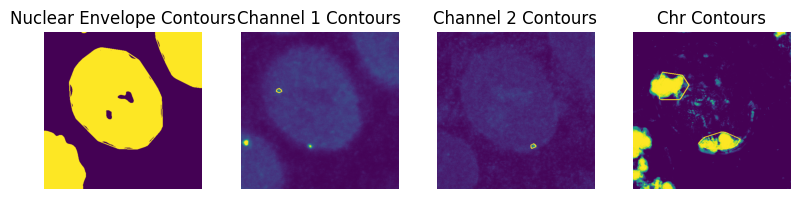

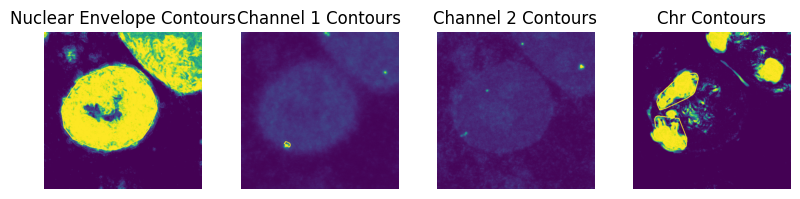

Skipping H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_4_tif_MIPs_series1_MIP.tif: No nuclear edges detected.


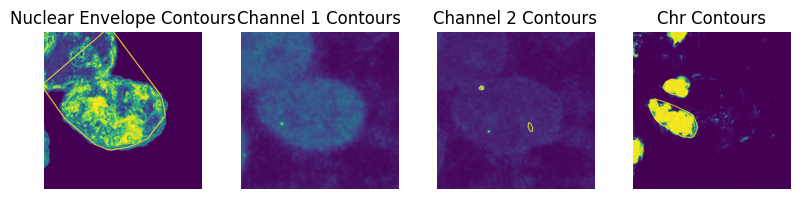

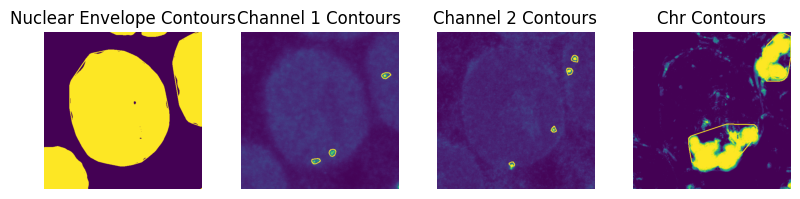

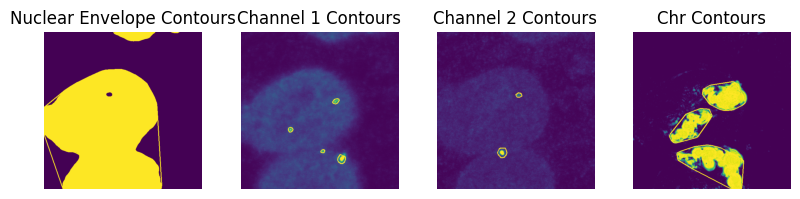

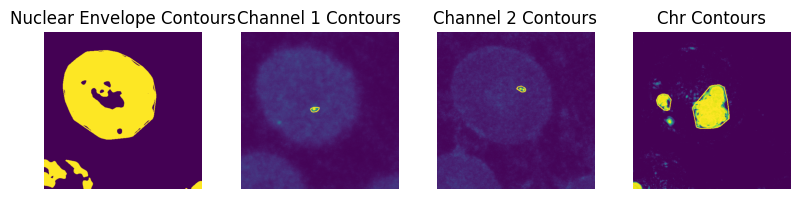

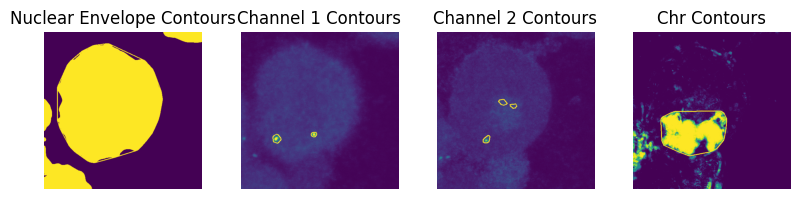

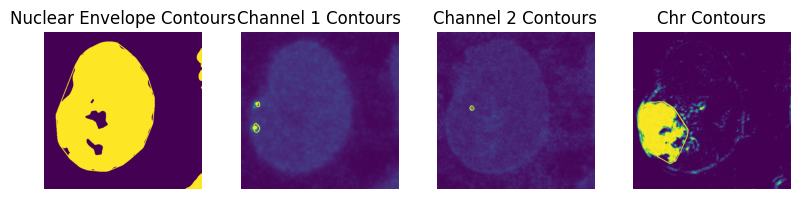

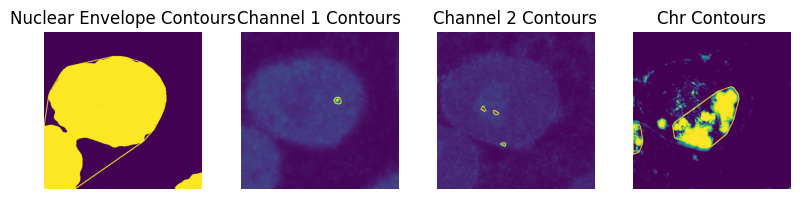

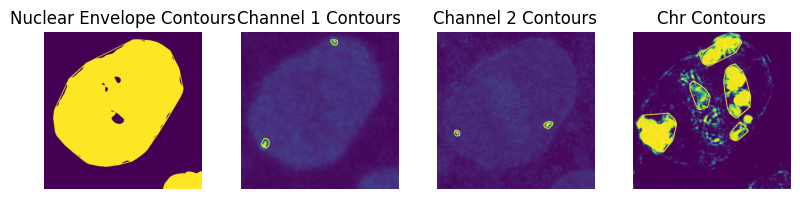

Skipping H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_54_tif_MIPs_series1_MIP.tif: No chromosome territory detected.


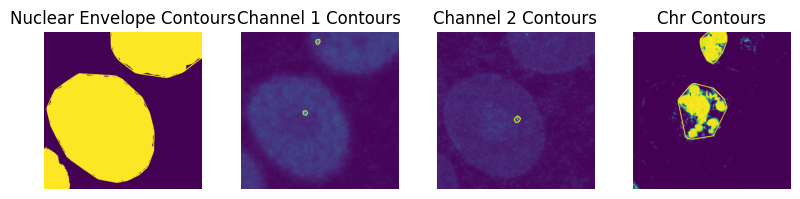

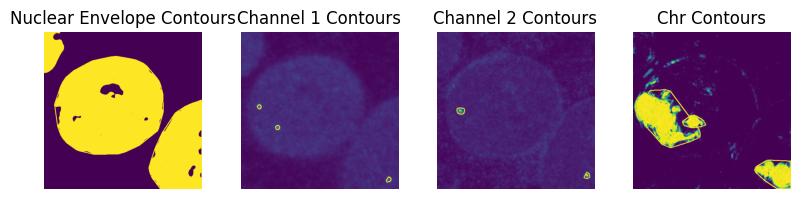

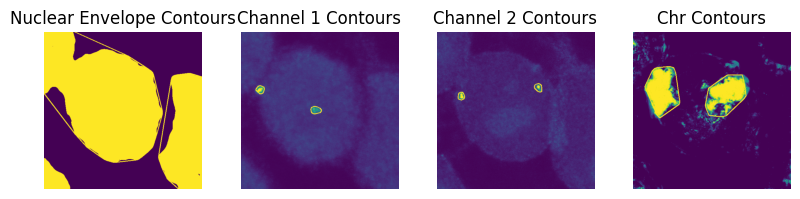

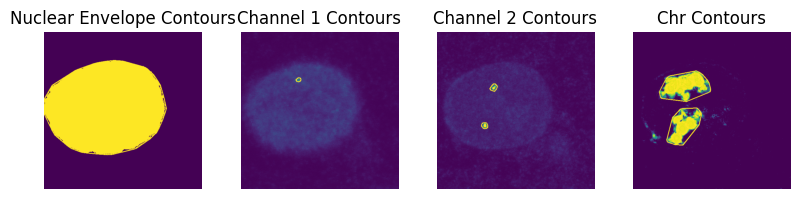

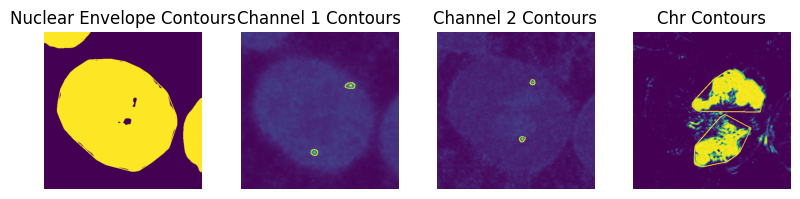

...

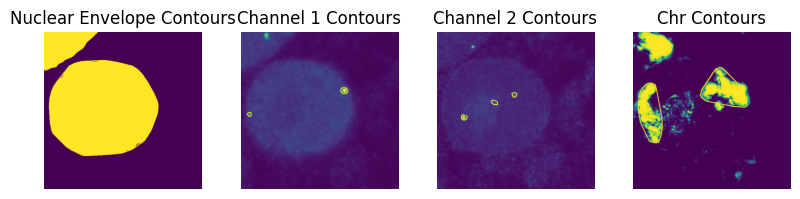

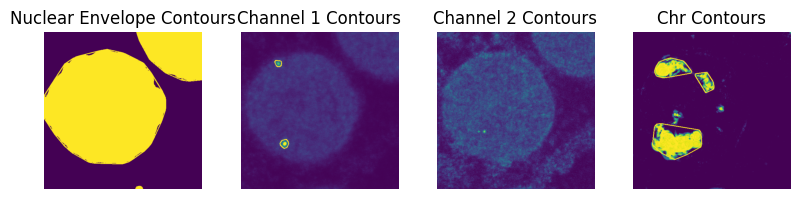

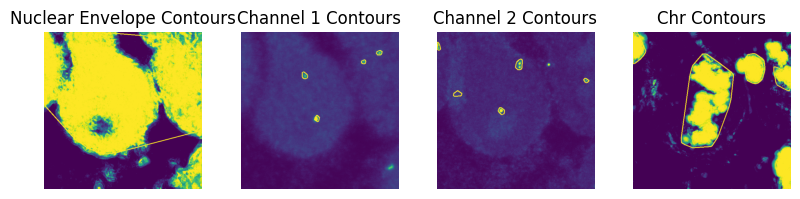

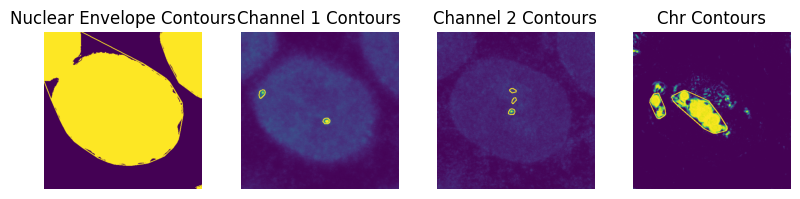

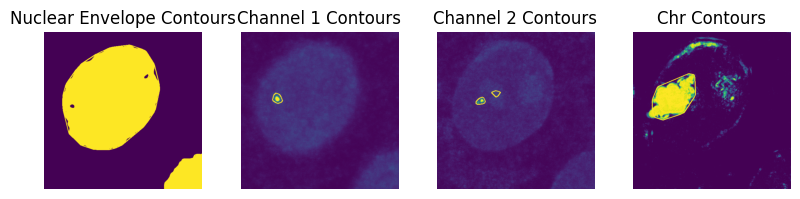

Skipping H1_chr11_488_chr11_88_647_chr11_41_550_tif_MIPs_series1_MIP.tif: No nuclear edges detected.
Skipping H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_1_tif_MIPs_series1_MIP.tif: No nuclear edges detected.
Skipping H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_47_tif_MIPs_series1_MIP.tif: No chromosome territory detected.


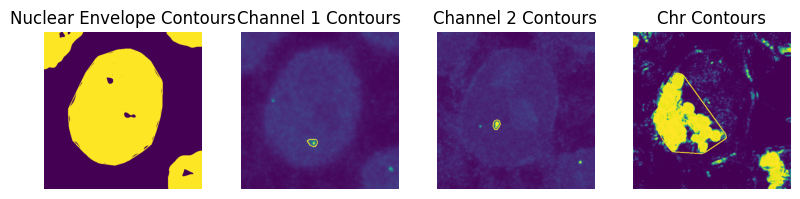

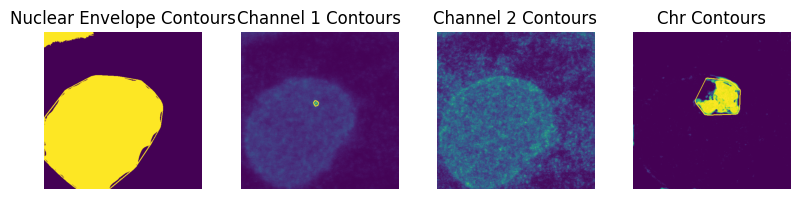

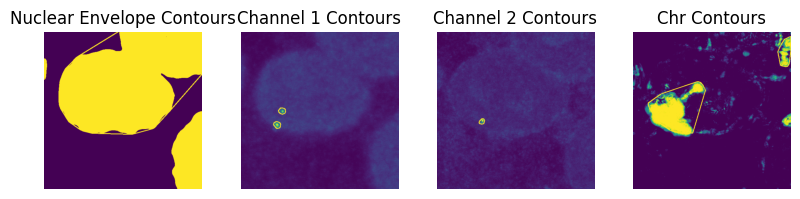

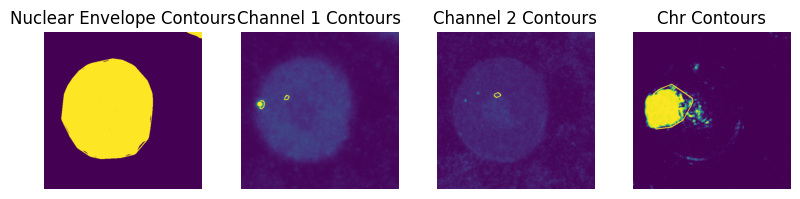

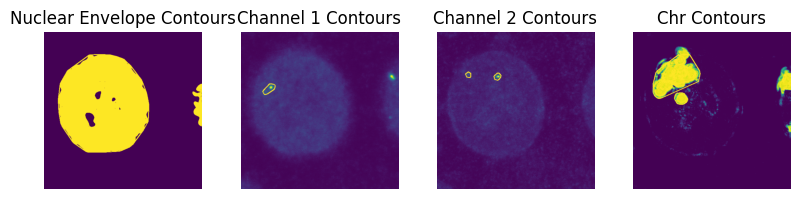

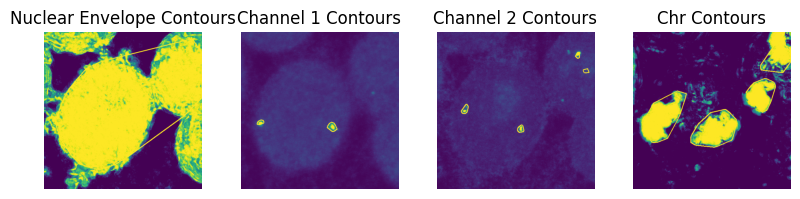

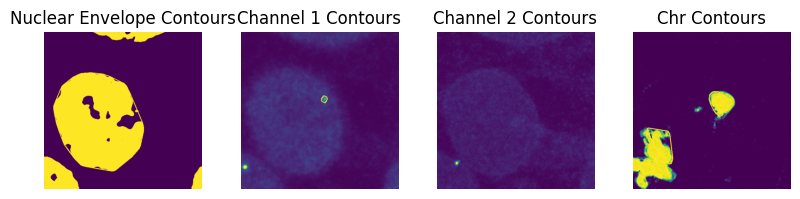

Skipping H1_chr11_488_chr11_88_647_chr11_41_550_1_tif_MIPs_series1_MIP.tif: No nuclear edges detected.


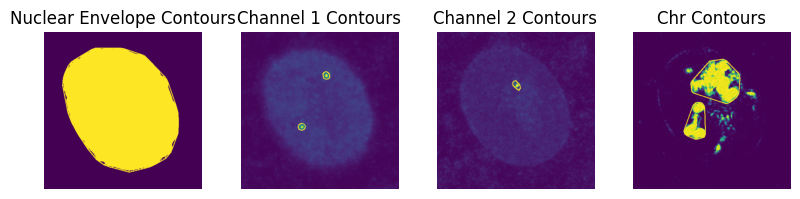

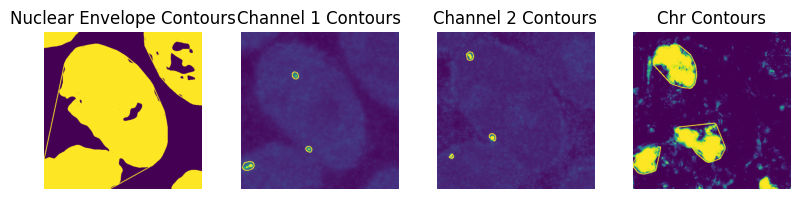

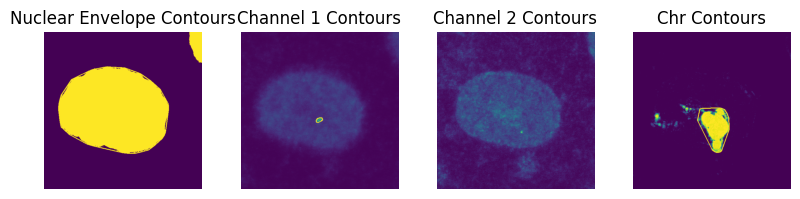

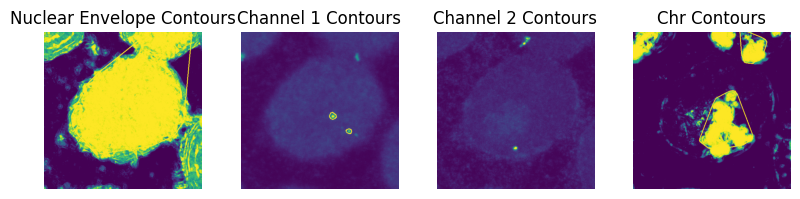

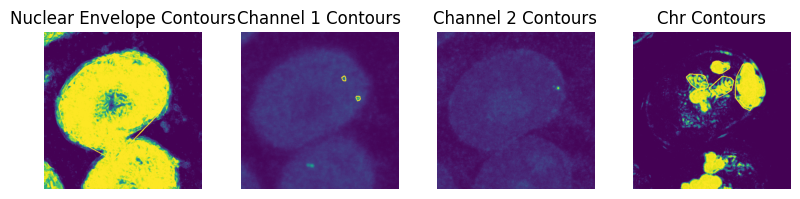

...

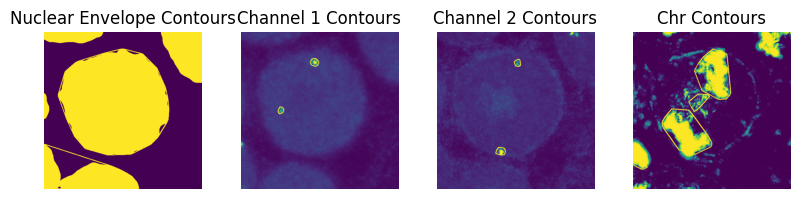

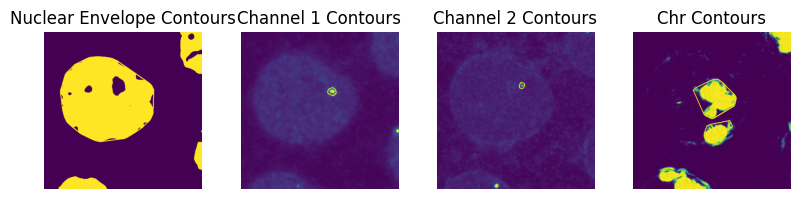

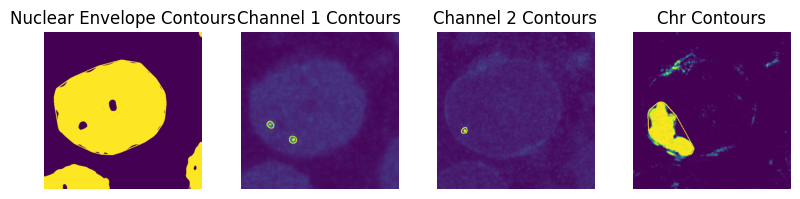

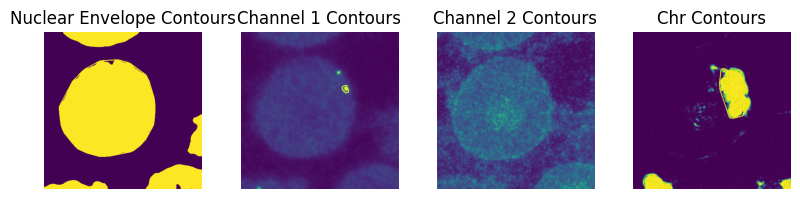

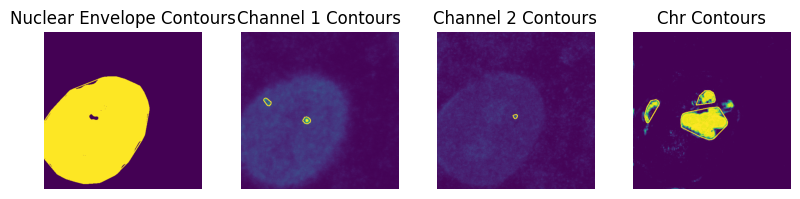

Skipping H1_chr11_488_chr11_88_647_chr11_41_550_2_-_Position_44_tif_MIPs_series1_MIP.tif: No nuclear edges detected.


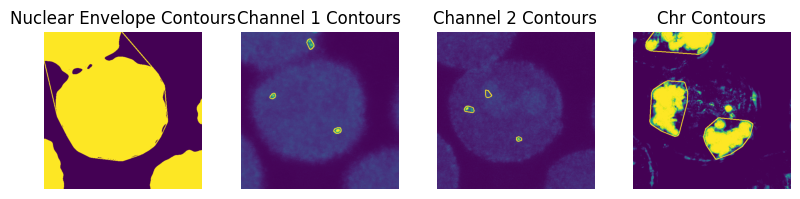

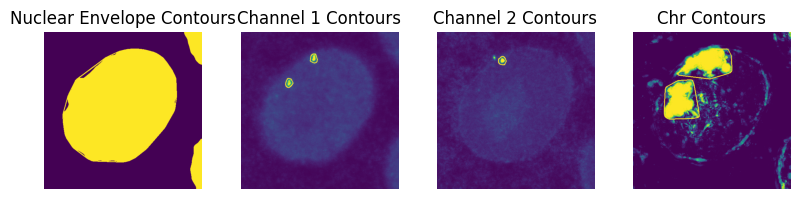

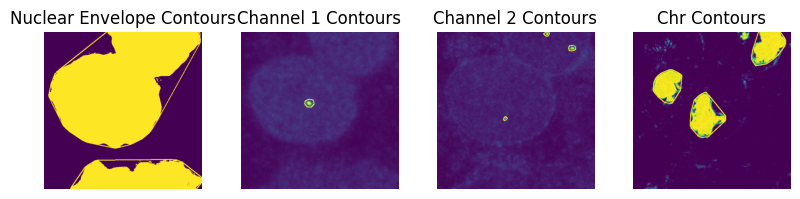

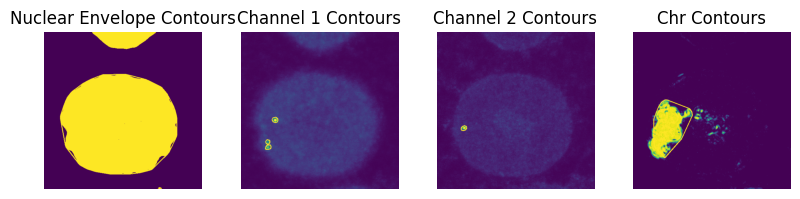

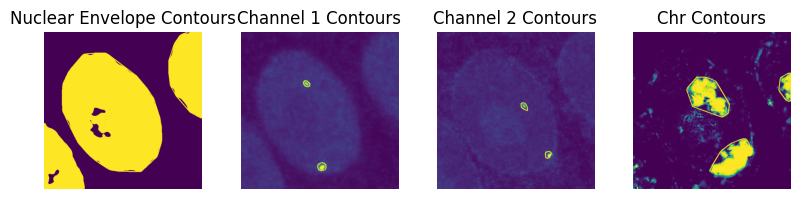

...

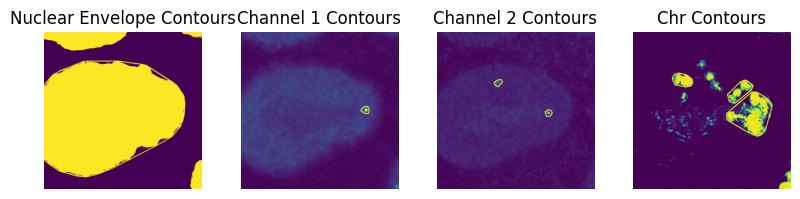

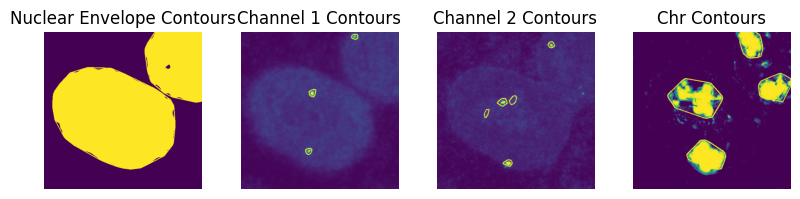

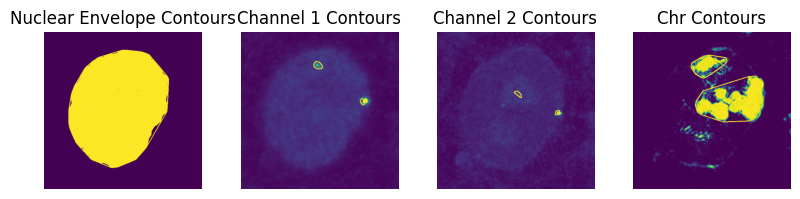

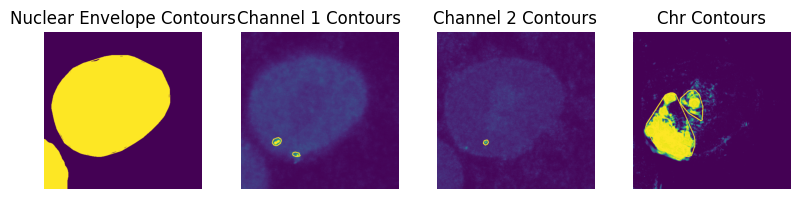

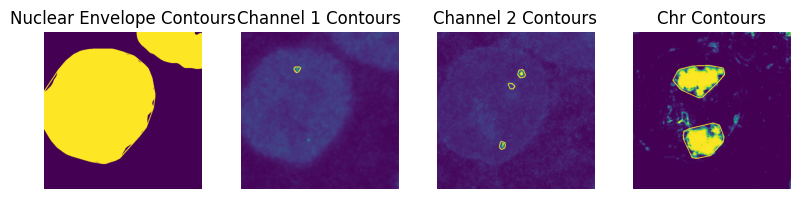

In [211]:
# Chr11_88 & Chr11_41 
#(H1-DE: threshold: nuclear: 80, dot_488: 100; dot_647: 80; chr_territory: 70; 
#iHep: nuclear load path, 1, nuclear: 72, dot_488: 120; dot_647: 80; mHep:nuclear: 72,dot_488: 120; dot_647: 80)
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_88_chr11_41/"
#tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif")]

stage = 'H1'
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif") and f.startswith((stage))]

print("550: Chr11_88; 647: chr11_41")

cluster_488 = []
cluster_647 = []

for file in tiff_files:  # Using all TIFF files
    image_path = os.path.join(data_dir, file)
    try:
        # Load required channels using tifffile
        image = tiff.imread(image_path)
        if len(image.shape) < 3 or image.shape[0] < 7:
            print(f"Skipping {file}: Not enough channels ({image.shape})")
            continue

        dot_488 = load_image_tifffile(image_path, 1)
        dot_647 = load_image_tifffile(image_path, 4)
        chr_territory = load_image_tifffile(image_path, 5)
        nuclear = load_image_tifffile(image_path, 6)

        # Ensure images are not empty
        if dot_488.size == 0 or dot_647.size == 0 or chr_territory.size == 0 or nuclear.size == 0:
            print(f"Skipping {file}: One or more image channels are empty.")
            continue

        # Extract nuclear morphology
        nuclear_region, num_nuclei, df_nuclear_edges = extract_nuclear_morphology(nuclear)

        # Check if nuclear region is empty
        if nuclear_region.size == 0:
            print(f"Skipping {file}: No nuclear region detected.")
            continue
        
        # Process chromosome territories within nuclear shape
        pixels_chr_territory, df_chr_territory = preprocess_image_within_chrterritory(chr_territory, nuclear_region)
        
        # Check if chromosome territory is empty
        if df_chr_territory.empty:
            print(f"Skipping {file}: No chromosome territory detected.")
            continue
        
        # Process dot detection
        binary1, df_488 = preprocess_image_within_dot488(dot_488, nuclear_region, top_pct=1)
        binary2, df_647 = preprocess_image_within_dot647(dot_647, nuclear_region, top_pct=5)

        # Ensure dot detection is not empty
        if df_488.empty and df_647.empty:
            print(f"Skipping {file}: No dots detected in 488 or 647 channels.")
            continue

        # Compute nuclear centroid using region properties
        nuclear_centroid = calculate_nuclear_centroid(nuclear_region, nuclear)

        # Check if nuclear edges are empty
        if df_nuclear_edges.empty:
            print(f"Skipping {file}: No nuclear edges detected.")
            continue

        # Calculate distances per dot
        df_488 = calculate_distances(df_488, df_nuclear_edges, nuclear_centroid, df_chr_territory, file)
        df_647 = calculate_distances(df_647, df_nuclear_edges, nuclear_centroid, df_chr_territory, file)

        # Store results separately in two clusters
        cluster_488.append(df_488)
        cluster_647.append(df_647)
    
        # Draw contours
        draw_contours(
            [nuclear, dot_488, dot_647, chr_territory], 
            [nuclear_region, binary1, binary2, pixels_chr_territory], 
            ["Nuclear Envelope Contours", "Channel 1 Contours", "Channel 2 Contours", "Chr Contours"], 
            [(255, 255, 255), (255, 0, 0), (255, 0, 0), (255, 0, 0)]
        )

    except Exception as e:
        print(f"Error processing {file}: {e}")

# Concatenate all DataFrames and save separately
if cluster_488:
    df_cluster_488 = pd.concat(cluster_488, ignore_index=True)
    df_cluster_488.to_csv(os.path.join(data_dir, f"{stage}_cluster_647_farest_dist_saved.csv"), index=False)

if cluster_647:
    df_cluster_647 = pd.concat(cluster_647, ignore_index=True)
    df_cluster_647.to_csv(os.path.join(data_dir, f"{stage}_cluster_550_farest_dist_saved.csv"), index=False)

In [222]:
len(df_cluster_647['File_Name'].unique())

54

In [35]:
df_cluster_488.head()

,Centroid_Y,Centroid_X,Max_Intensity,Area,File_Name,Dist_to_Nuclear_Centroid,Dist_to_Nuclear_Edge,Dist_Nuclear_Edge_to_Centroid,Dist_to_Chr_Territory_Edge,Dist_to_Chr_Territory_Centroid,Dist_Chr_Edge_to_Centroid,Max_Chr_Edge_to_Centroid
0,335.897025,82.750572,255.0,437.0,mHep_chr11_488_chr11_88_647_chr11_41_550_tif_M...,170.462615,14.881594,182.849473,8.088727,83.096392,83.215011,100.341130
1,239.545455,109.878788,255.0,330.0,mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_P...,147.966612,14.576136,162.463252,9.455322,63.618553,62.763509,108.069406
2,257.009646,218.443730,255.0,311.0,mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_P...,59.472216,49.867518,109.261416,25.032022,46.346271,55.080884,108.069406
3,356.122137,277.877863,241.0,131.0,mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_P...,140.836612,11.930751,137.784091,11.930751,14.161322,16.883907,96.590789
4,412.333333,288.849850,255.0,333.0,mHep_chr11_488_chr11_88_647_chr11_41_550_2_-_P...,198.105207,14.866019,210.491134,14.866019,45.015165,56.907019,96.590789


In [247]:
#get the nuclear territory
def extract_nuclear_morphology(image):
    """ Extract nuclear morphology from an image and get its edges. """
    # Convert to grayscale
    gray_image = color.rgb2gray(image) if len(image.shape) == 3 else image / 255.0
    
    # Enhance contrast with histogram equalization
    equalized_image = cv2.equalizeHist((gray_image * 255).astype(np.uint8))
    normalized_image = equalized_image / 255.0
    
    # Compute threshold for nuclear envelope (bottom 5% intensity)
    nuclear_threshold = np.percentile(normalized_image.flatten(), 95)
    nuclear_mask = normalized_image >= nuclear_threshold
    nuclear_mask = morphology.remove_small_objects(nuclear_mask, min_size=20000)  # Remove noise
    
    # Label connected components in the nuclear mask
    labeled_nuclei, num_labels = measure.label(nuclear_mask, connectivity=2, return_num=True)
    
    # Extract edges of nuclear envelope with labeled regions
    df_nuclear_edges = get_binary_edges_and_coordinates(nuclear_mask.astype(np.uint8) * 255, labeled_nuclei)
    
    #remove background
    df_nuclear_edges = df_nuclear_edges[df_nuclear_edges["Region_Label"] > 0]
    
    return labeled_nuclei, num_labels, df_nuclear_edges

In [287]:
#get the chromosome territory
def preprocess_image_within_chrterritory(image, nuclear_mask):
    """Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions."""
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask

    # Normalize only within nuclear regions
    min_val = np.min(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 0
    max_val = np.max(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 255
    normalized_image = np.zeros_like(gray, dtype=np.float32)
    if max_val > min_val:
        normalized_image[nuclear_mask > 0] = (gray[nuclear_mask > 0] - min_val) / (max_val - min_val)

    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply((normalized_image * 255).astype(np.uint8))

    # Determine threshold value within nuclear region
    binary = (enhanced > 90).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  # Remove noise
    
    # Label connected components
    labeled_regions, _ = measure.label(binary, connectivity=2, return_num=True)
    
    # Get edge coordinates with labeled regions
    df_edges = get_binary_edges_and_coordinates(binary, labeled_regions)
    
    #remove background
    df_edges = df_edges[df_edges["Region_Label"] > 0]

    return binary, df_edges

In [288]:
#get the chromosome territory
def preprocess_image_within_chrterritory_iHepmHep(image, nuclear_mask):
    """Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions."""
    
    # Convert image to uint8 format
    gray = image.astype(np.uint8)  

    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization) directly on gray image
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    # Determine threshold value within nuclear region
    binary = (enhanced > 80).astype(np.uint8) * 255

    # Remove small objects (noise)
    binary_cleaned = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  

    # Label connected components
    labeled_regions, _ = measure.label(binary_cleaned, connectivity=2, return_num=True)

    # Get edge coordinates with labeled regions
    df_edges = get_binary_edges_and_coordinates(binary_cleaned, labeled_regions)

    # Remove background (Ensure "Region_Label" exists in df_edges)
    if "Region_Label" in df_edges.columns:
        df_edges = df_edges[df_edges["Region_Label"] > 0]

    return binary_cleaned, df_edges

In [289]:
#get the nuclear territory
def extract_nuclear_morphology_iHepmHep(image):
    """ Extract nuclear morphology from an image and get its edges. """
    # Convert to grayscale
    gray_image = color.rgb2gray(image) if len(image.shape) == 3 else image / 255.0
    
    # Enhance contrast with histogram equalization
    equalized_image = cv2.equalizeHist((gray_image * 255).astype(np.uint8))
    normalized_image = equalized_image / 255.0
    
    # Compute threshold for nuclear envelope (bottom 5% intensity)
    nuclear_threshold = np.percentile(normalized_image.flatten(), 95)
    nuclear_mask = normalized_image >= nuclear_threshold
    nuclear_mask = morphology.remove_small_objects(nuclear_mask, min_size=10000)  # Remove noise
    
    # Label connected components in the nuclear mask
    labeled_nuclei, num_labels = measure.label(nuclear_mask, connectivity=2, return_num=True)
    
    # Extract edges of nuclear envelope with labeled regions
    df_nuclear_edges = get_binary_edges_and_coordinates(nuclear_mask.astype(np.uint8) * 255, labeled_nuclei)
    
    #remove background
    df_nuclear_edges = df_nuclear_edges[df_nuclear_edges["Region_Label"] > 0]
    
    return labeled_nuclei, num_labels, df_nuclear_edges

dot: Chr11_119; dot: chr11_107


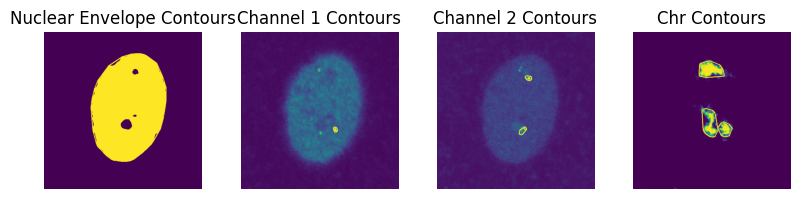

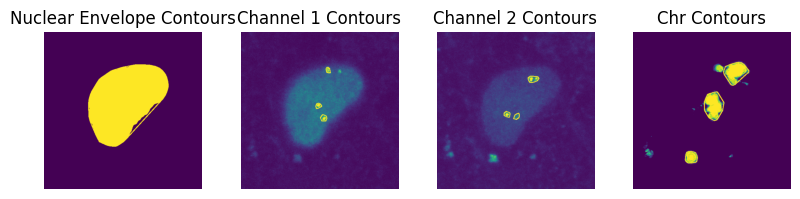

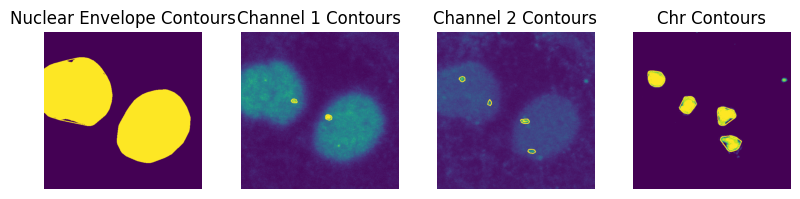

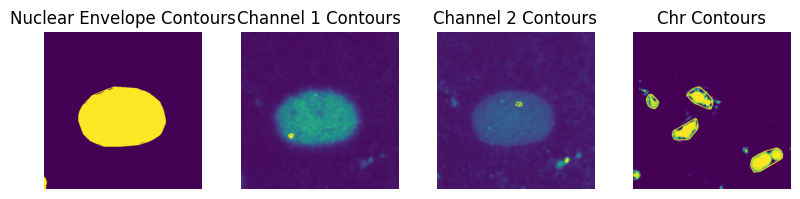

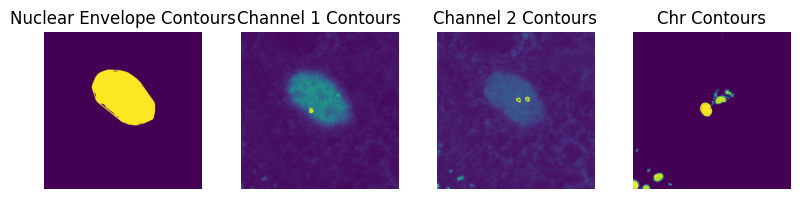

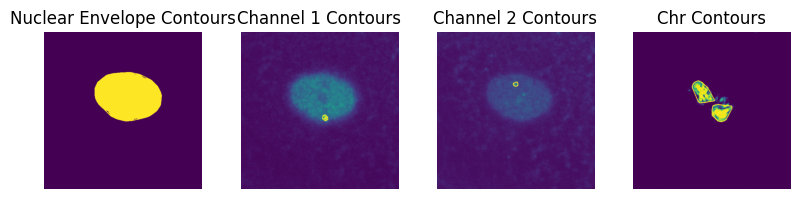

Skipping mHep_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_16_tif_MIPs__...p_chr11_488_chr11_107_647_chr11_119_550_2 - Position 16.tifseries1_MIP.tif: No dots detected in 488 and 647 channels.


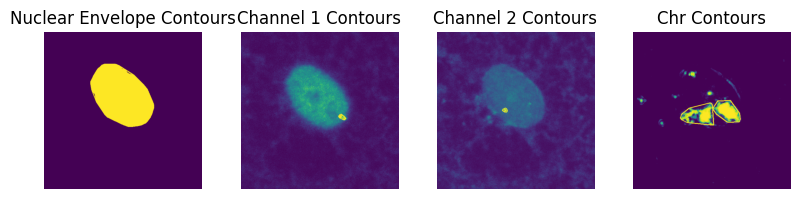

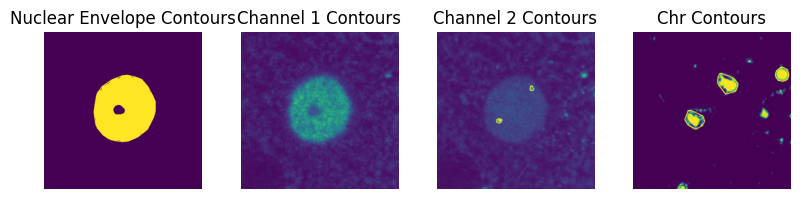

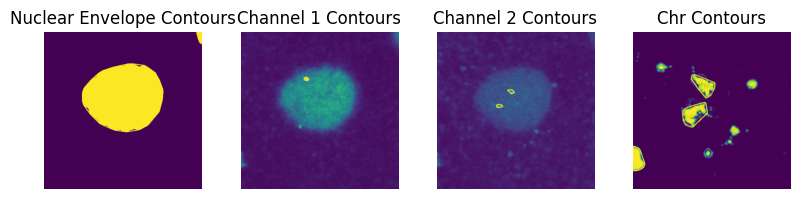

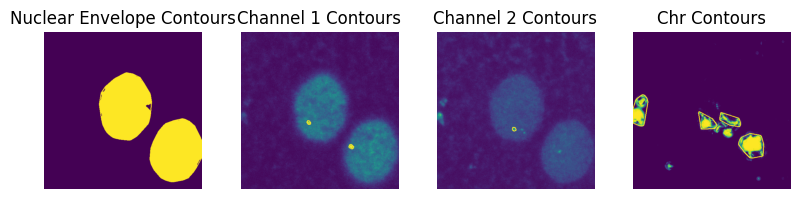

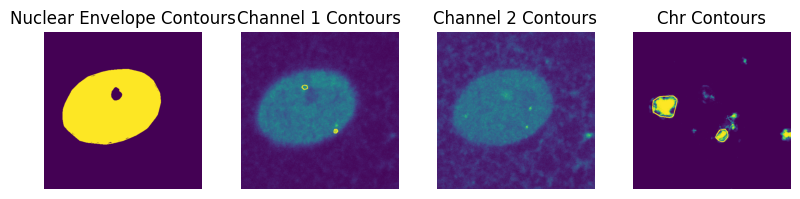

...

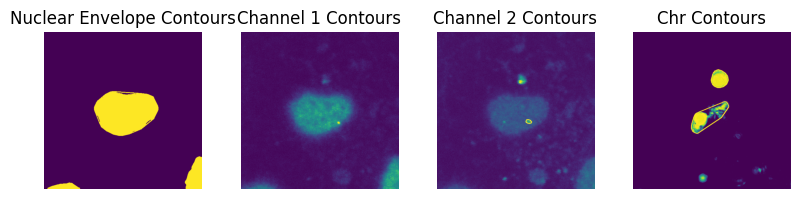

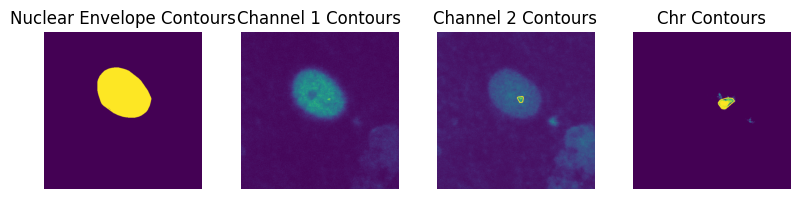

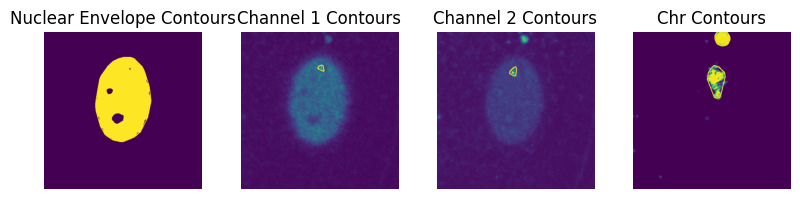

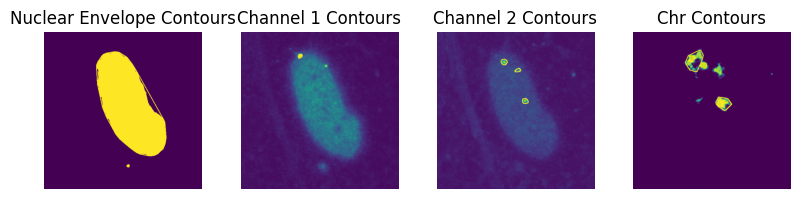

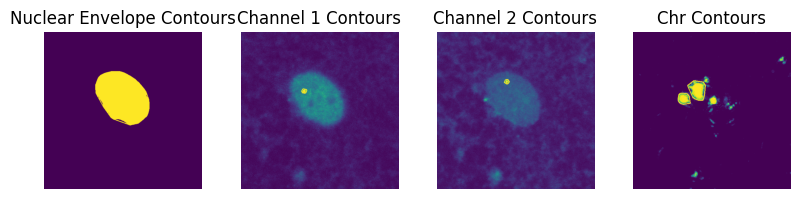

Skipping mHep_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_24_tif_MIPs__...p_chr11_488_chr11_107_647_chr11_119_550_2 - Position 24.tifseries1_MIP.tif: No chromosome territory detected.


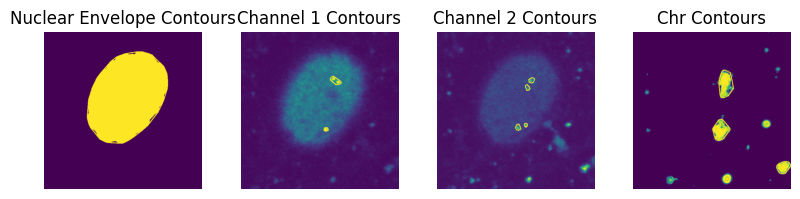

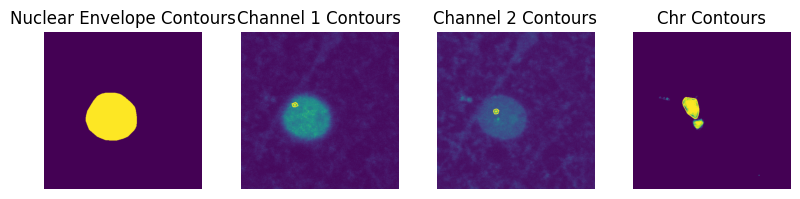

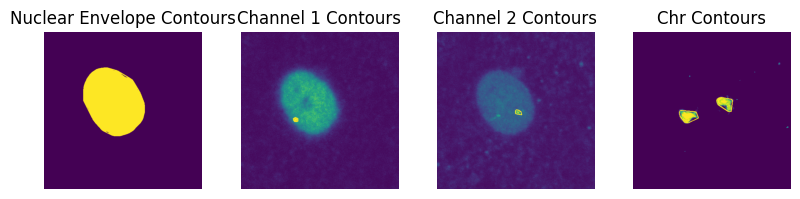

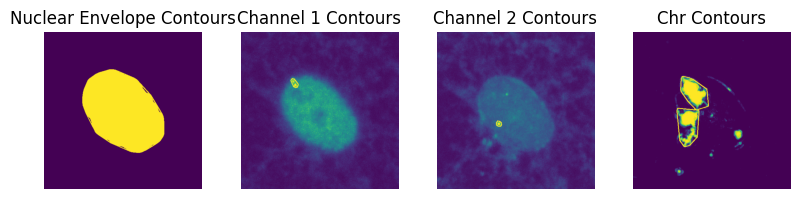

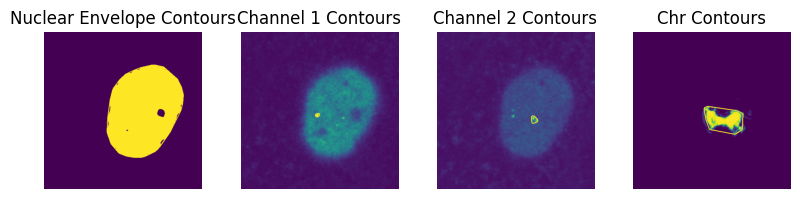

...

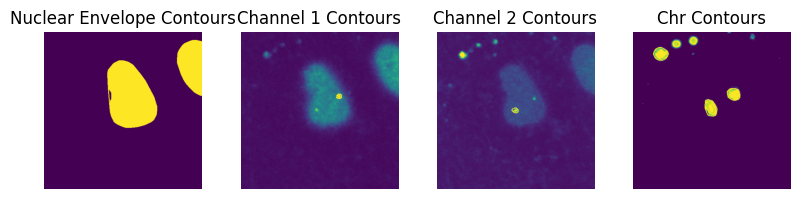

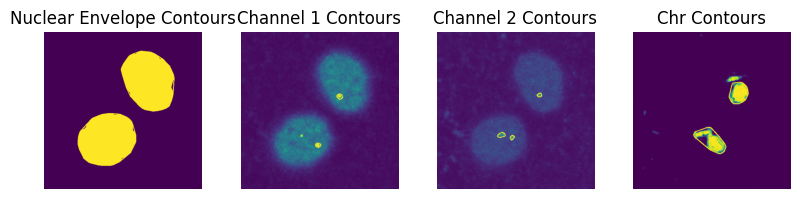

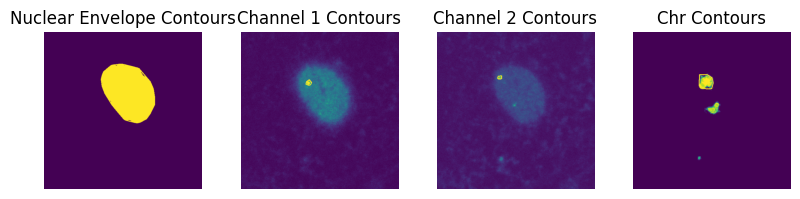

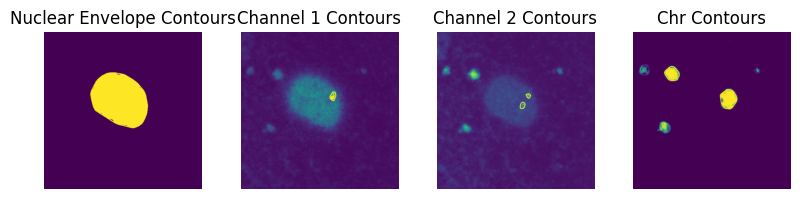

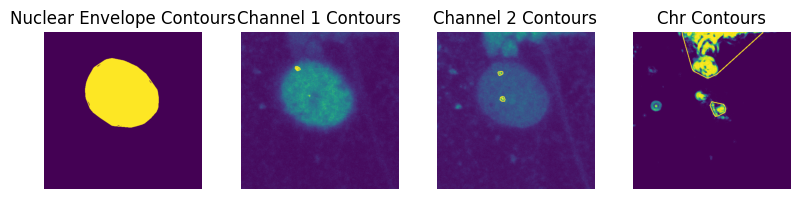

Skipping mHep_chr11_488_chr11_107_647_chr11_119_550_2_-_Position_14_tif_MIPs__...p_chr11_488_chr11_107_647_chr11_119_550_2 - Position 14.tifseries1_MIP.tif: No dots detected in 488 and 647 channels.


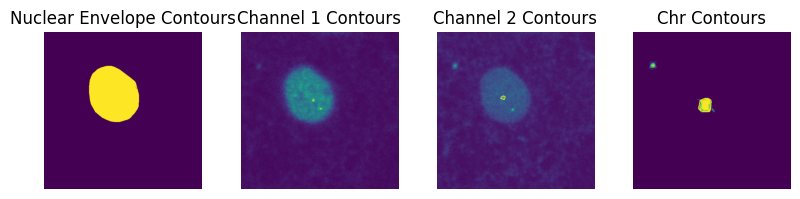

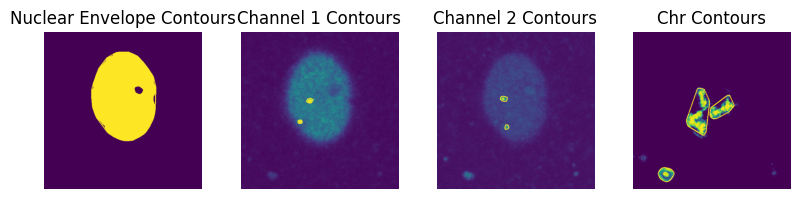

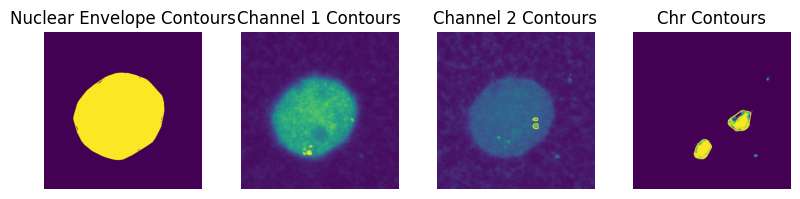

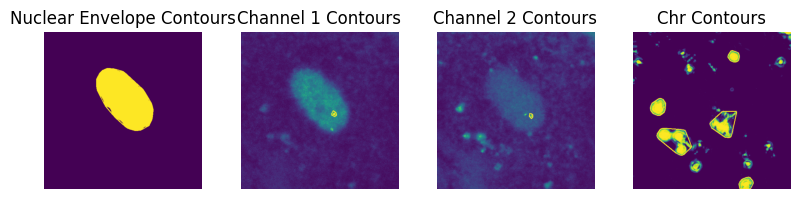

In [291]:
# Chr11_107 & Chr11_119 (threshold: nuclear: 80, dot_488: 180; dot_647: 120; chr_territory: 80)
#(H1: threshold: nuclear: 80, dot_488: 160; dot_647: 90; chr_territory: 80; 
#DE: threshold: nuclear: 80, dot_488: 210; dot_647: 150; chr_territory: 80; 
#HB: threshold: nuclear: 95, dot_488: 140; dot_647: 140; chr_territory: 80; 
#iHep: nuclear: 95, dot_488: 200; dot_647: 160;dot_647: 80; chr_territory: 80; 
#mHep:nuclear: 95,dot_488: 160; dot_647: 120; chr_territory: 80; )
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_107_chr11_119/"
#tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif")]
stage = 'mHep'
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif") and f.startswith((stage))]

print("dot: Chr11_119; dot: chr11_107")

cluster_488 = []
cluster_647 = []

for file in tiff_files:  # Using all TIFF files
    image_path = os.path.join(data_dir, file)
    try:
        # Load required channels using tifffile
        image = tiff.imread(image_path)
        if len(image.shape) < 3 or image.shape[0] < 7:
            print(f"Skipping {file}: Not enough channels ({image.shape})")
            continue

        dot_488 = load_image_tifffile(image_path, 1)
        dot_647 = load_image_tifffile(image_path, 4)
        chr_territory = load_image_tifffile(image_path, 5)
        nuclear = load_image_tifffile(image_path, 6)
                # Ensure images are not empty
        if dot_488.size == 0 or dot_647.size == 0 or chr_territory.size == 0 or nuclear.size == 0:
            print(f"Skipping {file}: One or more image channels are empty.")
            continue

        # Extract nuclear morphology
#        nuclear_region, num_nuclei, df_nuclear_edges = extract_nuclear_morphology(nuclear)
        nuclear_region, num_nuclei, df_nuclear_edges = extract_nuclear_morphology_iHepmHep(nuclear)


        # Check if nuclear region is empty
        if nuclear_region.size == 0:
            print(f"Skipping {file}: No nuclear region detected.")
            continue
        
        # Process chromosome territories within nuclear shape
#        pixels_chr_territory, df_chr_territory = preprocess_image_within_chrterritory(chr_territory, nuclear_region)
        pixels_chr_territory, df_chr_territory = preprocess_image_within_chrterritory_iHepmHep(chr_territory, nuclear_region)

        # Check if chromosome territory is empty
        if df_chr_territory.empty:
            print(f"Skipping {file}: No chromosome territory detected.")
            continue
        
        # Process dot detection
        binary1, df_488 = preprocess_image_within_dot488(dot_488, nuclear_region, top_pct=7)
        binary2, df_647 = preprocess_image_within_dot647(dot_647, nuclear_region, top_pct=3)

        # Ensure dot detection is not empty
        if df_488.empty and df_647.empty:
            print(f"Skipping {file}: No dots detected in 488 and 647 channels.")
            continue

        # Compute nuclear centroid using region properties
        nuclear_centroid = calculate_nuclear_centroid(nuclear_region, nuclear)

        # Check if nuclear edges are empty
        if df_nuclear_edges.empty:
            print(f"Skipping {file}: No nuclear edges detected.")
            continue

        # Calculate distances per dot
        df_488 = calculate_distances(df_488, df_nuclear_edges, nuclear_centroid, df_chr_territory, file)
        df_647 = calculate_distances(df_647, df_nuclear_edges, nuclear_centroid, df_chr_territory, file)

        # Store results separately in two clusters
        cluster_488.append(df_488)
        cluster_647.append(df_647)
        
        # Draw contours
        draw_contours(
            [nuclear, dot_488, dot_647, chr_territory], 
            [nuclear_region, binary1, binary2, pixels_chr_territory], 
            ["Nuclear Envelope Contours", "Channel 1 Contours", "Channel 2 Contours", "Chr Contours"], 
            [(255, 255, 255), (255, 0, 0), (255, 0, 0), (255, 0, 0)]
        )

    except Exception as e:
        print(f"Error processing {file}: {e}")

# Concatenate all DataFrames and save separately
if cluster_488:
    df_cluster_488 = pd.concat(cluster_488, ignore_index=True)
    df_cluster_488.to_csv(os.path.join(data_dir, f"{stage}_cluster_647_farest_dist_saved.csv"), index=False)

if cluster_647:
    df_cluster_647 = pd.concat(cluster_647, ignore_index=True)
    df_cluster_647.to_csv(os.path.join(data_dir, f"{stage}_cluster_550_farest_dist_saved.csv"), index=False)

In [252]:
len(df_cluster_488['File_Name'].unique())

50

In [108]:
df_cluster_488

,Centroid_Y,Centroid_X,Max_Intensity,Area,File_Name,Dist_to_Nuclear_Centroid,Dist_to_Nuclear_Edge,Dist_Nuclear_Edge_to_Centroid,Dist_to_Chr_Territory_Edge,Dist_to_Chr_Territory_Centroid,Dist_Chr_Edge_to_Centroid,Max_Chr_Edge_to_Centroid
0,145.347107,162.966942,254.0,121.0,H1_chr11_488_chr11_107_647_chr11_119_550_5_-_P...,216.778529,60.970438,241.681318,3.454199,90.718192,87.356968,116.397331
1,220.210959,265.849315,255.0,365.0,H1_chr11_488_chr11_107_647_chr11_119_550_5_-_P...,137.063632,100.580228,220.639081,1.169863,38.006392,38.993578,116.397331
2,99.735294,124.205882,255.0,170.0,H1_chr11_488_chr11_107_647_chr11_119_550_5_-_P...,218.224273,5.625111,223.832412,6.249291,141.000954,146.204719,396.772177
3,275.829787,222.835590,255.0,517.0,H1_chr11_488_chr11_107_647_chr11_119_550_5_-_P...,87.551663,43.906220,126.760357,4.765274,83.797451,80.305667,396.772177
4,460.640351,467.105263,255.0,228.0,H1_chr11_488_chr11_107_647_chr11_119_550_5_-_P...,284.735625,5.360683,289.007246,18.359951,357.695034,371.595514,396.772177
...,...,...,...,...,...,...,...,...,...,...,...,...
290,338.371041,226.416290,255.0,221.0,H1_chr11_488_chr11_107_647_chr11_119_550_5_-_P...,177.301988,17.710304,194.889445,0.557645,141.273211,140.907298,297.986779
291,218.097436,169.723077,255.0,195.0,H1_chr11_488_chr11_107_647_chr11_119_550_4_-_P...,88.062550,35.246881,120.919106,1.725830,149.036247,150.416795,405.133537
292,299.172185,289.019868,255.0,151.0,H1_chr11_488_chr11_107_647_chr11_119_550_4_-_P...,61.428528,14.864629,47.060881,12.388720,16.350494,4.530245,405.133537
293,402.466667,486.748148,255.0,135.0,H1_chr11_488_chr11_107_647_chr11_119_550_4_-_P...,283.510237,58.623593,315.508989,23.649440,221.581806,198.159768,405.133537


In [223]:
#get the nuclear territory
def extract_nuclear_morphology(image):
    """ Extract nuclear morphology from an image and get its edges. """
    # Convert to grayscale
    gray_image = color.rgb2gray(image) if len(image.shape) == 3 else image / 255.0
    
    # Enhance contrast with histogram equalization
    equalized_image = cv2.equalizeHist((gray_image * 255).astype(np.uint8))
    normalized_image = equalized_image / 255.0
    
    # Compute threshold for nuclear envelope (bottom 5% intensity)
    nuclear_threshold = np.percentile(normalized_image.flatten(), 90)
    nuclear_mask = normalized_image >= nuclear_threshold
    nuclear_mask = morphology.remove_small_objects(nuclear_mask, min_size=50000)  # Remove noise
    
    # Label connected components in the nuclear mask
    labeled_nuclei, num_labels = measure.label(nuclear_mask, connectivity=2, return_num=True)
    
    # Extract edges of nuclear envelope with labeled regions
    df_nuclear_edges = get_binary_edges_and_coordinates(nuclear_mask.astype(np.uint8) * 255, labeled_nuclei)
    
    #remove background
    df_nuclear_edges = df_nuclear_edges[df_nuclear_edges["Region_Label"] > 0]
    
    return labeled_nuclei, num_labels, df_nuclear_edges

In [229]:
#get the chromosome territory
def preprocess_image_within_chrterritory(image, nuclear_mask):
    """Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions."""
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask

    # Normalize only within nuclear regions
    min_val = np.min(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 0
    max_val = np.max(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 255
    normalized_image = np.zeros_like(gray, dtype=np.float32)
    if max_val > min_val:
        normalized_image[nuclear_mask > 0] = (gray[nuclear_mask > 0] - min_val) / (max_val - min_val)

    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply((normalized_image * 255).astype(np.uint8))

    # Determine threshold value within nuclear region
    binary = (enhanced > 65).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  # Remove noise
    
    # Label connected components
    labeled_regions, _ = measure.label(binary, connectivity=2, return_num=True)
    
    # Get edge coordinates with labeled regions
    df_edges = get_binary_edges_and_coordinates(binary, labeled_regions)
    
    #remove background
    df_edges = df_edges[df_edges["Region_Label"] > 0]

    return binary, df_edges

In [87]:
#get the chromosome territory
def preprocess_image_within_chrterritory_iHepmHep(image):
    """Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions."""
    
    # Convert image to uint8 format
    gray = image.astype(np.uint8)  

    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization) directly on gray image
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    # Determine threshold value within nuclear region
    binary = (enhanced > 80).astype(np.uint8) * 255

    # Remove small objects (noise)
    binary_cleaned = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  

    # Label connected components
    labeled_regions, _ = measure.label(binary_cleaned, connectivity=2, return_num=True)

    # Get edge coordinates with labeled regions
    df_edges = get_binary_edges_and_coordinates(binary_cleaned, labeled_regions)

    # Remove background (Ensure "Region_Label" exists in df_edges)
    if "Region_Label" in df_edges.columns:
        df_edges = df_edges[df_edges["Region_Label"] > 0]

    return binary_cleaned, df_edges

In [49]:
def extract_nuclear_morphology_iHepmHep(image):
    """ Extract nuclear morphology from an image and get its edges. """   
    # Convert image to uint8 format
    gray = image.astype(np.uint8)  

    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    # Apply fixed threshold value
    threshold = 3  # Identified optimal threshold
    binary = (enhanced > threshold).astype(np.uint8) * 255

    # Remove small objects (noise)
    binary_cleaned = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  

    # Label connected components
    labeled_regions, num_labels = measure.label(binary_cleaned, connectivity=2, return_num=True)
    
    # Get edge coordinates with labeled regions
    df_edges = get_binary_edges_and_coordinates(binary_cleaned, labeled_regions)

    # Remove background (Ensure "Region_Label" exists in df_edges)
    if "Region_Label" in df_edges.columns: 
        df_edges = df_edges[df_edges["Region_Label"] > 0]


    return binary_cleaned, num_labels, df_edges

In [ ]:
# Chr11_11 & Chr11_41 
#(H1 threshold: nuclear: 90, dot_488: 160; dot_647: 105; chr_territory: 80) 
#(DE threshold: load image 6 as nuclear; nuclear: 90, dot_488: 190; dot_647: 160; chr_territory: 80)
#(HB threshold: load image 6 as nuclear; nuclear: 85, dot_488: 170; dot_647: 140; chr_territory: 80)
#(iHep threshold: load image 6 as nuclear; nuclear: 3, dot_488: 170; dot_647: 140; chr_territory: 80)
#(mHep threshold: load image 6 as nuclear; nuclear: 3, dot_488: 160; dot_647: 140; chr_territory: 80)
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_11_chr11_41/"
#tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif")]

stage = 'H1'
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif") and f.startswith((stage))]


print("550: Chr11_11; 647: chr11_41")

cluster_488 = []
cluster_647 = []

for file in tiff_files:  # Using all TIFF files
    image_path = os.path.join(data_dir, file)
    try:
        # Load required channels using tifffile
        image = tiff.imread(image_path)
        if len(image.shape) < 3 or image.shape[0] < 7:
            print(f"Skipping {file}: Not enough channels ({image.shape})")
            continue

        dot_488 = load_image_tifffile(image_path, 1)
        dot_647 = load_image_tifffile(image_path, 4)
        chr_territory = load_image_tifffile(image_path, 5)
        nuclear = load_image_tifffile(image_path, 6)
        
        # Extract nuclear morphology
        nuclear_region, num_nuclei, df_nuclear_edges = extract_nuclear_morphology_iHepmHep(nuclear)


        # Check if nuclear region is empty
        if nuclear_region.size == 0:
            print(f"Skipping {file}: No nuclear region detected.")
            continue
        
        # Process chromosome territories within nuclear shape
        pixels_chr_territory, df_chr_territory = preprocess_image_within_chrterritory_iHepmHep(chr_territory)

        # Check if chromosome territory is empty
        if df_chr_territory.empty:
            print(f"Skipping {file}: No chromosome territory detected.")
            continue
        
        # Process dot detection
        binary1, df_488 = preprocess_image_within_dot488(dot_488, nuclear_region, top_pct=5)
        binary2, df_647 = preprocess_image_within_dot647(dot_647, nuclear_region, top_pct=5)

        # Ensure dot detection is not empty
        if df_488.empty and df_647.empty:
            print(f"Skipping {file}: No dots detected in 488 and 647 channels.")
            continue
        

        # Compute nuclear centroid using region properties
        nuclear_centroid = calculate_nuclear_centroid(nuclear_region, nuclear)

        # Check if nuclear edges are empty
        if df_nuclear_edges.empty:
            print(f"Skipping {file}: No nuclear edges detected.")
            continue

        # Calculate distances per dot
        df_488 = calculate_distances(df_488, df_nuclear_edges, nuclear_centroid, df_chr_territory, file)
        df_647 = calculate_distances(df_647, df_nuclear_edges, nuclear_centroid, df_chr_territory, file)
        
        # Store results separately in two clusters
        cluster_488.append(df_488)
        cluster_647.append(df_647)
        
        # Draw contours
        draw_contours(
            [nuclear, dot_488, dot_647, chr_territory], 
            [nuclear_region, binary1, binary2, pixels_chr_territory], 
            ["Nuclear Envelope Contours", "Channel 1 Contours", "Channel 2 Contours", "Chr Contours"], 
            [(255, 255, 255), (255, 0, 0), (255, 0, 0), (255, 0, 0)]
        )

    except Exception as e:
        print(f"Error processing {file}: {e}")

# Concatenate all DataFrames and save separately
if cluster_488:
    df_cluster_488 = pd.concat(cluster_488, ignore_index=True)
    df_cluster_488.to_csv(os.path.join(data_dir, f"{stage}_cluster_647_farest_dist_saved.csv"), index=False)

if cluster_647:
    df_cluster_647 = pd.concat(cluster_647, ignore_index=True)
    df_cluster_647.to_csv(os.path.join(data_dir, f"{stage}_cluster_550_farest_dist_saved.csv"), index=False)

In [231]:
len(df_cluster_647['File_Name'].unique())

84

In [324]:
# Check which file names start with 'H1'
starts_with_H1 = df_cluster_488['File_Name'].astype(str).str.startswith('H1')
# Get count of unique file names that start with 'H1'
len(df_cluster_488.loc[starts_with_H1, 'File_Name'].unique())

89

In [ ]:
df_cluster_488.head()

# dots in Chr2

In [138]:
#get the nuclear territory
def extract_nuclear_morphology(image):
    """ Extract nuclear morphology from an image and get its edges. """
    # Convert to grayscale
    gray_image = color.rgb2gray(image) if len(image.shape) == 3 else image / 255.0
    
    # Enhance contrast with histogram equalization
    equalized_image = cv2.equalizeHist((gray_image * 255).astype(np.uint8))
    normalized_image = equalized_image / 255.0
    
    # Compute threshold for nuclear envelope (bottom 5% intensity)
    nuclear_threshold = np.percentile(normalized_image.flatten(), 90)
    nuclear_mask = normalized_image >= nuclear_threshold
    nuclear_mask = morphology.remove_small_objects(nuclear_mask, min_size=20000)  # Remove noise
    
    # Label connected components in the nuclear mask
    labeled_nuclei, num_labels = measure.label(nuclear_mask, connectivity=2, return_num=True)
    
    # Extract edges of nuclear envelope with labeled regions
    df_nuclear_edges = get_binary_edges_and_coordinates(nuclear_mask.astype(np.uint8) * 255, labeled_nuclei)
    
    #remove background
    df_nuclear_edges = df_nuclear_edges[df_nuclear_edges["Region_Label"] > 0]
    
    return labeled_nuclei, num_labels, df_nuclear_edges

In [134]:
#get the chromosome territory
def preprocess_image_within_chrterritory_iHepmHep(image):
    """Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions."""
    
    # Convert image to uint8 format
    gray = image.astype(np.uint8)  

    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization) directly on gray image
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    # Determine threshold value within nuclear region
    binary = (enhanced > 90).astype(np.uint8) * 255

    # Remove small objects (noise)
    binary_cleaned = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  

    # Label connected components
    labeled_regions, _ = measure.label(binary_cleaned, connectivity=2, return_num=True)

    # Get edge coordinates with labeled regions
    df_edges = get_binary_edges_and_coordinates(binary_cleaned, labeled_regions)

    # Remove background (Ensure "Region_Label" exists in df_edges)
    if "Region_Label" in df_edges.columns:
        df_edges = df_edges[df_edges["Region_Label"] > 0]

    return binary_cleaned, df_edges

In [158]:
#get the chromosome territory
def preprocess_image_within_chrterritory(image, nuclear_mask):
    """Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions."""
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask

    # Normalize only within nuclear regions
    min_val = np.min(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 0
    max_val = np.max(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 255
    normalized_image = np.zeros_like(gray, dtype=np.float32)
    if max_val > min_val:
        normalized_image[nuclear_mask > 0] = (gray[nuclear_mask > 0] - min_val) / (max_val - min_val)

    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply((normalized_image * 255).astype(np.uint8))

    # Determine threshold value within nuclear region
    binary = (enhanced > 150).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  # Remove noise
    
    # Label connected components
    labeled_regions = measure.label(binary, connectivity=2)
    regions = measure.regionprops(labeled_regions)
    
    # Filter regions based on roundness (circularity)
    filtered_binary = np.zeros_like(binary, dtype=np.uint8)
    for region in regions:
        if region.perimeter > 0:
            roundness = (4 * np.pi * region.area) / (region.perimeter ** 2)
            if roundness <= 0.6:  # Keep only regions with roundness <= 0.8
                filtered_binary[labeled_regions == region.label] = 255
    
    # Get edge coordinates with labeled regions
    filtered_labeled_regions = measure.label(filtered_binary, connectivity=2)
    df_edges = get_binary_edges_and_coordinates(filtered_binary, filtered_labeled_regions)
    
    # Remove background
    df_edges = df_edges[df_edges["Region_Label"] > 0]
    
    return filtered_binary, df_edges

In [ ]:
# Chr2_2 & Chr2_32 
#(H1 threshold: nuclear: 80, dot_488: 150; dot_647: 95; chr_territory: 150, if load image.shape[4])
#(DE threshold: nuclear: 80, dot_488: 160; dot_647: 95; chr_territory: 140, if load image.shape[4])
#(HB threshold: nuclear: 80, dot_488: 160; dot_647: 95; chr_territory: 160, if load image.shape[4])
#(iHep threshold: nuclear: 80, dot_488: 170; dot_647: 95; chr_territory: 170, if load image.shape[4])
#(mHep threshold: nuclear: 80, dot_488: 170; dot_647: 95; chr_territory: 170, if load image.shape[4])
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr2_2_chr2_32/"
#tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif")]

stage = 'H1'
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif") and f.startswith((stage))]


print("dot: Chr2_32; dot: chr2_2")

cluster_488 = []
cluster_647 = []

for file in tiff_files:  # Using all TIFF files
    image_path = os.path.join(data_dir, file)
    try:
        # Load required channels using tifffile
#        image = tiff.imread(image_path)
#        if len(image.shape) < 3 or image.shape[0] < 7:
#            print(f"Skipping {file}: Not enough channels ({image.shape})")
#            continue
            
        # Ensure image has at least 3 dimensions
        if len(image.shape) < 3:
            print(f"Skipping {file}: Expected a 3D image but found {image.shape}")
            continue

        # Ensure image has enough channels
        if image.shape[0] < 7:
            print(f"Skipping {file}: Not enough channels ({image.shape})")
            continue

        dot_488 = load_image_tifffile(image_path, 1)
        dot_647 = load_image_tifffile(image_path, 2)
        chr_territory = load_image_tifffile(image_path, 4)
        nuclear = load_image_tifffile(image_path, 6)
        
        # Extract nuclear morphology
        nuclear_region, num_nuclei, df_nuclear_edges = extract_nuclear_morphology(nuclear)
#        nuclear_region, num_nuclei, df_nuclear_edges = extract_nuclear_morphology_iHepmHep(nuclear)


        # Check if nuclear region is empty
        if nuclear_region.size == 0:
            print(f"Skipping {file}: No nuclear region detected.")
            continue
        
        # Process chromosome territories within nuclear shape
        pixels_chr_territory, df_chr_territory = preprocess_image_within_chrterritory(chr_territory, nuclear_region)
#        pixels_chr_territory, df_chr_territory = preprocess_image_within_chrterritory_iHepmHep(chr_territory)

        # Check if chromosome territory is empty
        if df_chr_territory.empty:
            print(f"Skipping {file}: No chromosome territory detected.")
            continue
        
        # Process dot detection
        binary1, df_488 = preprocess_image_within_dot488(dot_488, nuclear_region, top_pct=1)
        binary2, df_647 = preprocess_image_within_dot647(dot_647, nuclear_region, top_pct=3)

        # Ensure dot detection is not empty
        if df_488.empty and df_647.empty:
            print(f"Skipping {file}: No dots detected in 488 or 647 channels.")
            continue

        # Compute nuclear centroid using region properties
        nuclear_centroid = calculate_nuclear_centroid(nuclear_region, nuclear)

        # Check if nuclear edges are empty
        if df_nuclear_edges.empty:
            print(f"Skipping {file}: No nuclear edges detected.")
            continue

        # Calculate distances per dot
        df_488 = calculate_distances(df_488, df_nuclear_edges, nuclear_centroid, df_chr_territory, file)
        df_647 = calculate_distances(df_647, df_nuclear_edges, nuclear_centroid, df_chr_territory, file)
           
        # Store results separately in two clusters
        cluster_488.append(df_488)
        cluster_647.append(df_647)
        
        # Draw contours
        draw_contours(
            [nuclear, dot_488, dot_647, chr_territory], 
            [nuclear_region, binary1, binary2, pixels_chr_territory], 
            ["Nuclear Envelope Contours", "Channel 1 Contours", "Channel 2 Contours", "Chr Contours"], 
            [(255, 255, 255), (255, 0, 0), (255, 0, 0), (255, 0, 0)]
        )

    except Exception as e:
        print(f"Error processing {file}: {e}")

# Concatenate all DataFrames and save separately
if cluster_488:
    df_cluster_488 = pd.concat(cluster_488, ignore_index=True)
    df_cluster_488.to_csv(os.path.join(data_dir, f"{stage}_cluster_647_farest_dist_saved.csv"), index=False)

if cluster_647:
    df_cluster_647 = pd.concat(cluster_647, ignore_index=True)
    df_cluster_647.to_csv(os.path.join(data_dir, f"{stage}_cluster_488_farest_dist_saved.csv"), index=False)

In [160]:
len(df_cluster_488['File_Name'].unique())

37

In [161]:
#get the chromosome territory
def preprocess_image_within_chrterritory_iHepmHep(image):
    """Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions."""
    
    # Convert image to uint8 format
    gray = image.astype(np.uint8)  

    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization) directly on gray image
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    # Determine threshold value within nuclear region
    binary = (enhanced > 130).astype(np.uint8) * 255

    # Remove small objects (noise)
    binary_cleaned = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  

    # Label connected components
    labeled_regions, _ = measure.label(binary_cleaned, connectivity=2, return_num=True)

    # Get edge coordinates with labeled regions
    df_edges = get_binary_edges_and_coordinates(binary_cleaned, labeled_regions)

    # Remove background (Ensure "Region_Label" exists in df_edges)
    if "Region_Label" in df_edges.columns:
        df_edges = df_edges[df_edges["Region_Label"] > 0]

    return binary_cleaned, df_edges

In [169]:
#get the chromosome territory
def preprocess_image_within_chrterritory(image, nuclear_mask):
    """Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions."""
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask

    # Normalize only within nuclear regions
    min_val = np.min(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 0
    max_val = np.max(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 255
    normalized_image = np.zeros_like(gray, dtype=np.float32)
    if max_val > min_val:
        normalized_image[nuclear_mask > 0] = (gray[nuclear_mask > 0] - min_val) / (max_val - min_val)

    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply((normalized_image * 255).astype(np.uint8))

    # Determine threshold value within nuclear region
    binary = (enhanced > 160).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  # Remove noise
    
    # Label connected components
    labeled_regions = measure.label(binary, connectivity=2)
    regions = measure.regionprops(labeled_regions)
    
    # Filter regions based on roundness (circularity)
    filtered_binary = np.zeros_like(binary, dtype=np.uint8)
    for region in regions:
        if region.perimeter > 0:
            roundness = (4 * np.pi * region.area) / (region.perimeter ** 2)
            if roundness <= 0.6:  # Keep only regions with roundness <= 0.8
                filtered_binary[labeled_regions == region.label] = 255
    
    # Get edge coordinates with labeled regions
    filtered_labeled_regions = measure.label(filtered_binary, connectivity=2)
    df_edges = get_binary_edges_and_coordinates(filtered_binary, filtered_labeled_regions)
    
    # Remove background
    df_edges = df_edges[df_edges["Region_Label"] > 0]
    
    return filtered_binary, df_edges

dot: Chr2_79; dot: chr2_100


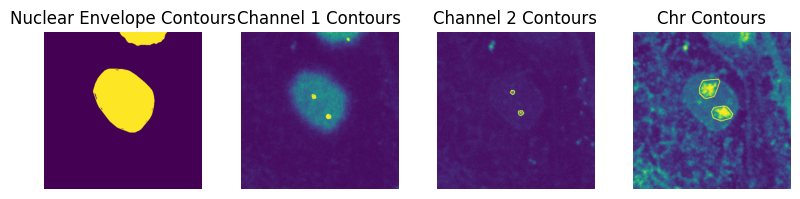

Skipping mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Position_18_tif_MIPs_series1_MIP.tif: No dots detected in 488 or 647 channels.


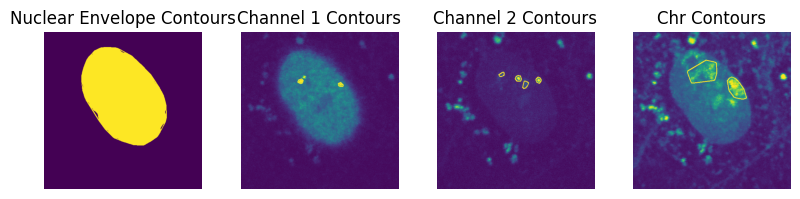

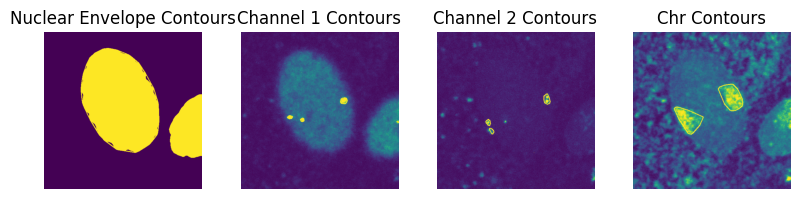

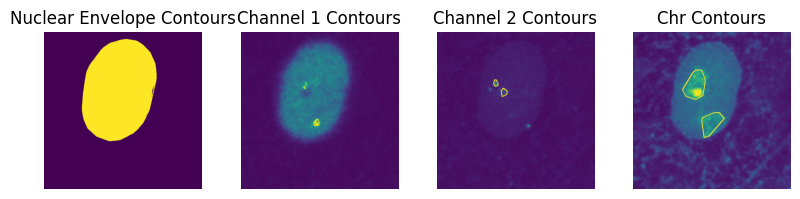

Skipping mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Position_27_tif_MIPs_series1_MIP.tif: No chromosome territory detected.


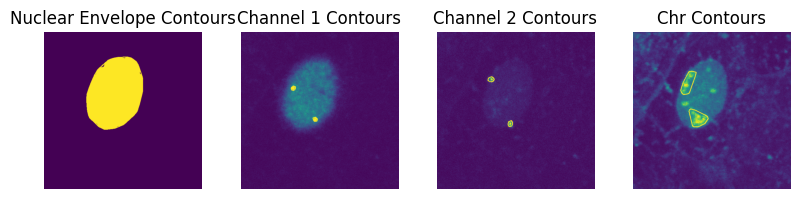

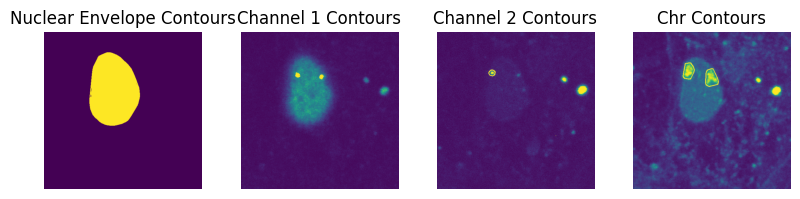

Skipping mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Position_60_tif_MIPs_series1_MIP.tif: No chromosome territory detected.


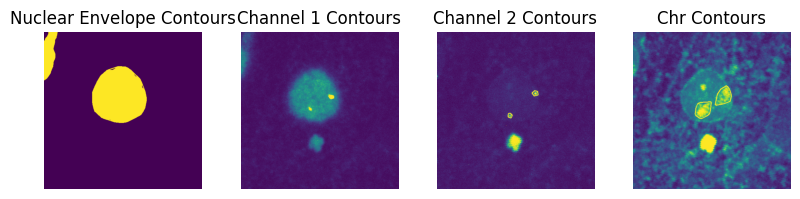

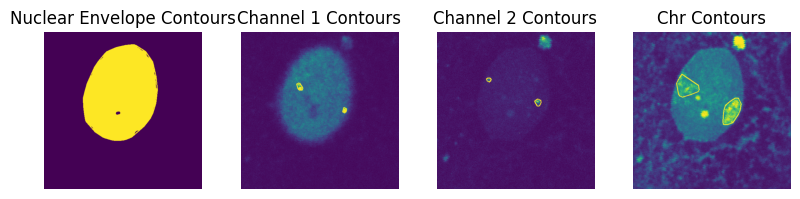

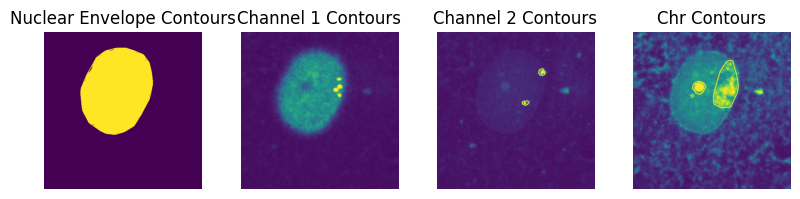

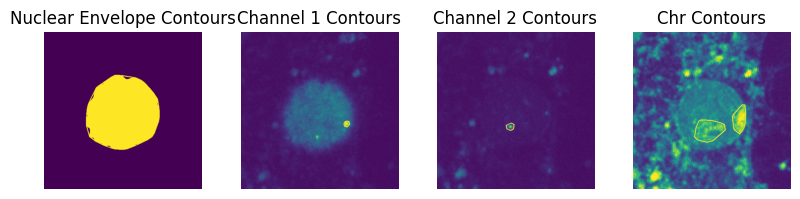

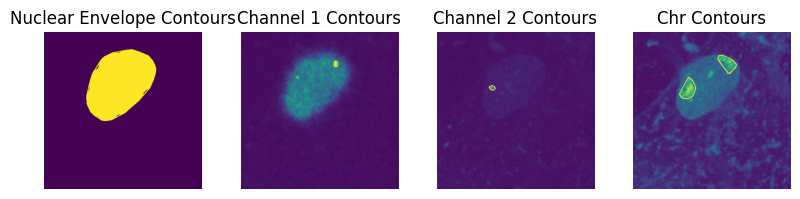

Skipping mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Position_52_tif_MIPs_series1_MIP.tif: No dots detected in 488 or 647 channels.


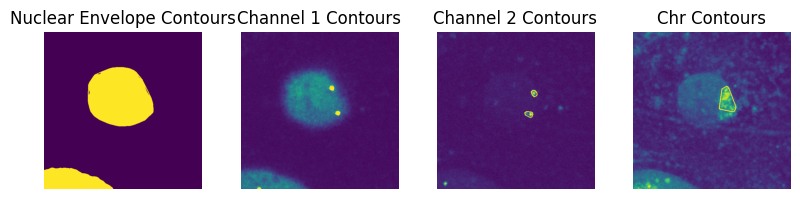

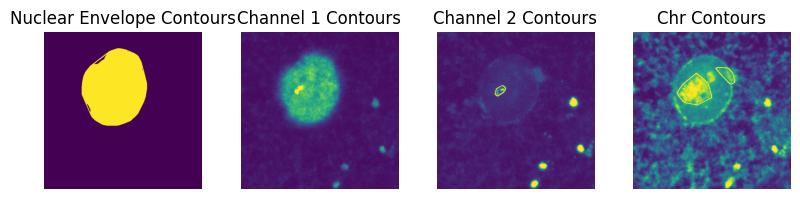

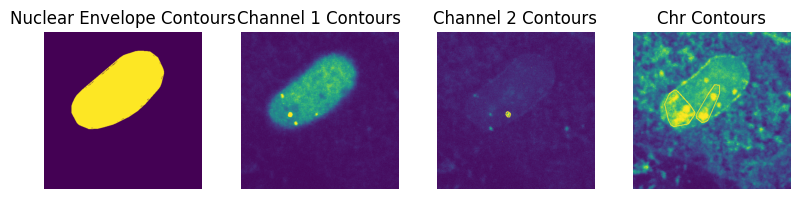

Skipping mHep_chr2_550_chr2_2_647_chr2_32_488_2_-_Position_29_tif_MIPs_series1_MIP.tif: No dots detected in 488 or 647 channels.


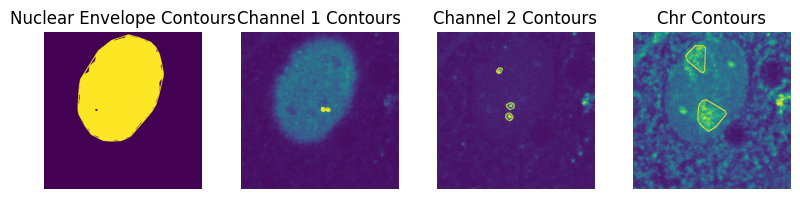

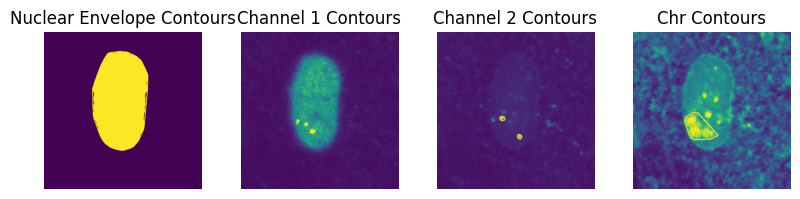

Skipping mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Position_19_tif_MIPs_series1_MIP.tif: No nuclear edges detected.


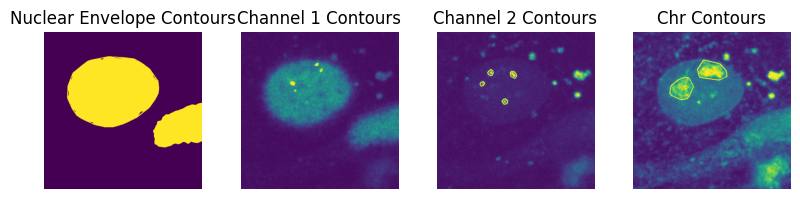

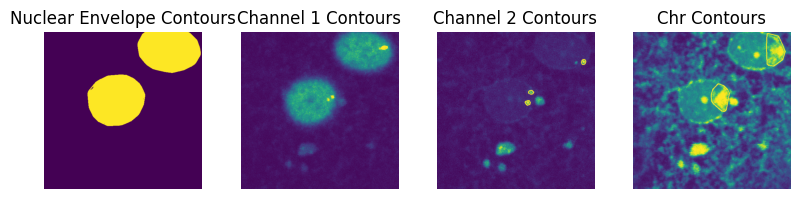

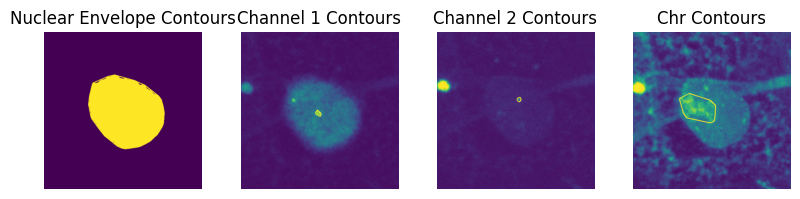

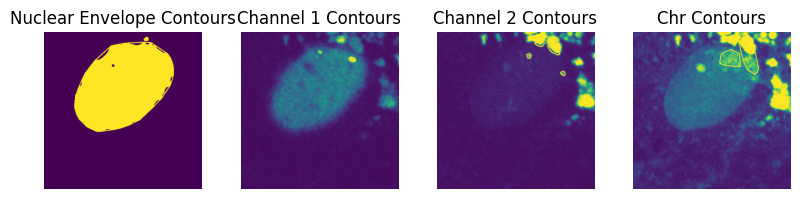

Skipping mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Position_22_tif_MIPs_series1_MIP.tif: No dots detected in 488 or 647 channels.


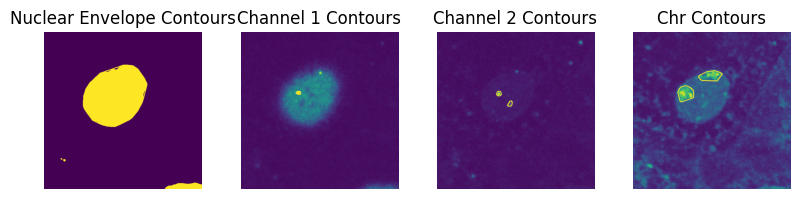

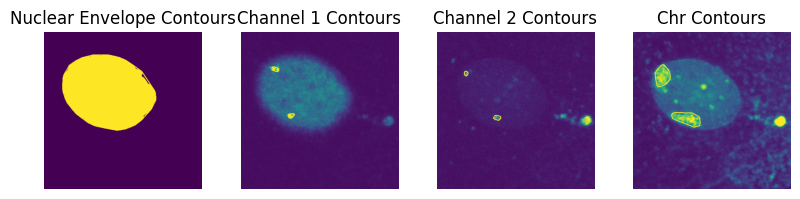

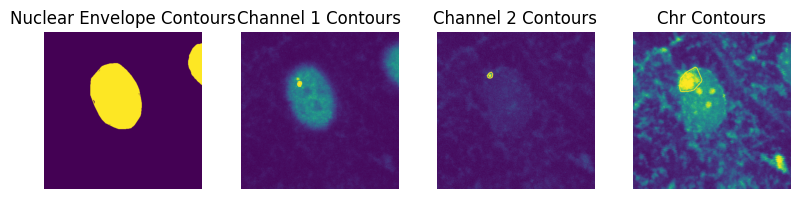

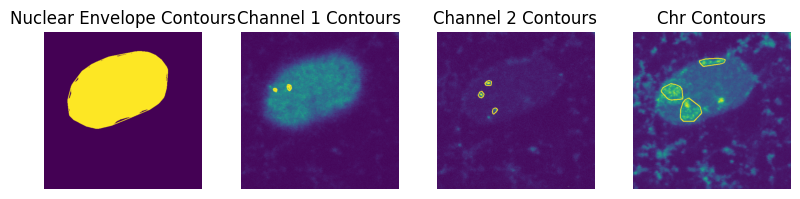

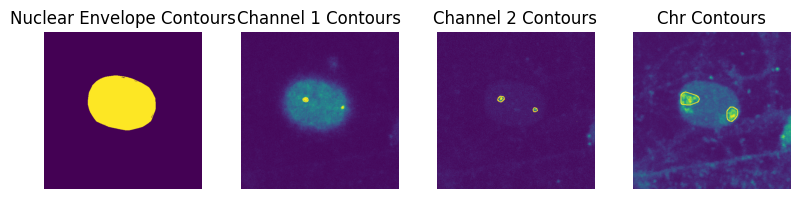

Skipping mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Position_58_tif_MIPs_series1_MIP.tif: No dots detected in 488 or 647 channels.


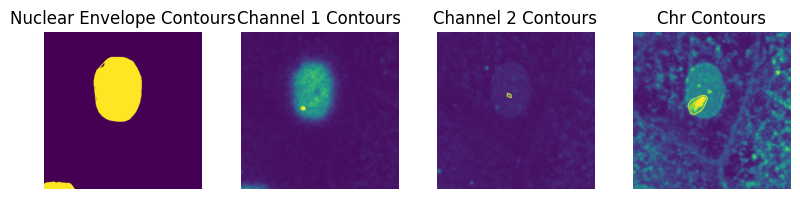

Skipping mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Position_63_tif_MIPs_series1_MIP.tif: No dots detected in 488 or 647 channels.


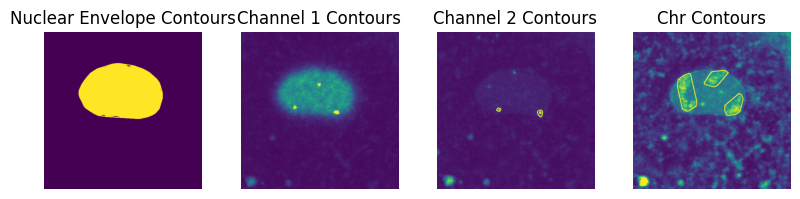

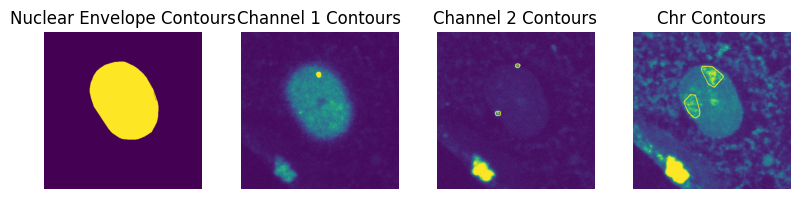

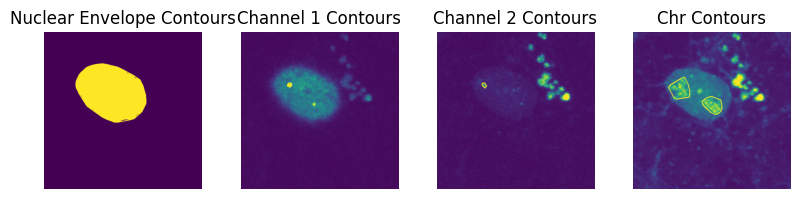

Skipping mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Position_13_tif_MIPs_series1_MIP.tif: No dots detected in 488 or 647 channels.


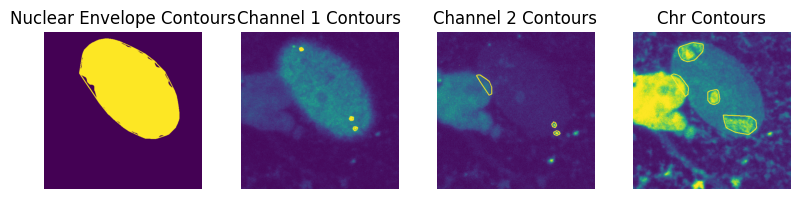

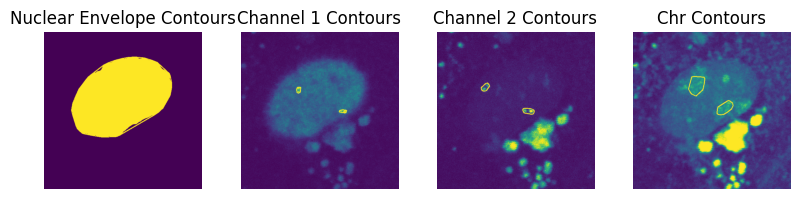

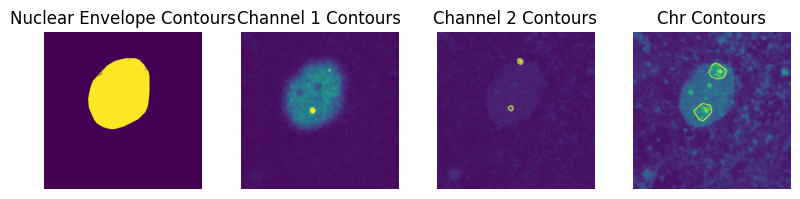

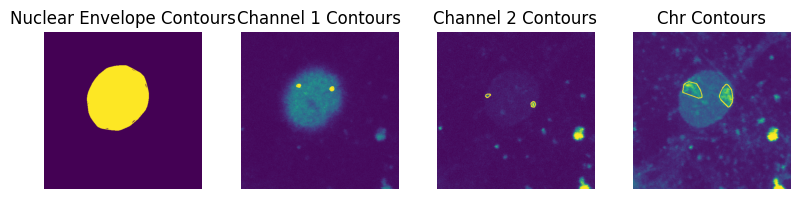

Skipping mHep_chr2_550_chr2_2_647_chr2_32_488_2_-_Position_65_tif_MIPs_series1_MIP.tif: No dots detected in 488 or 647 channels.


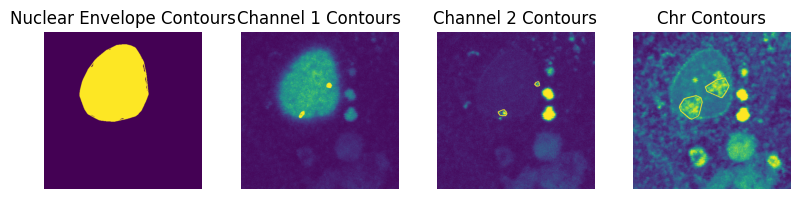

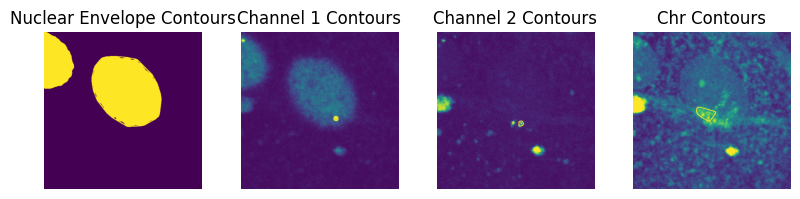

Skipping mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Position_43_tif_MIPs_series1_MIP.tif: No nuclear edges detected.
Skipping mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Position_29_tif_MIPs_series1_MIP.tif: No dots detected in 488 or 647 channels.


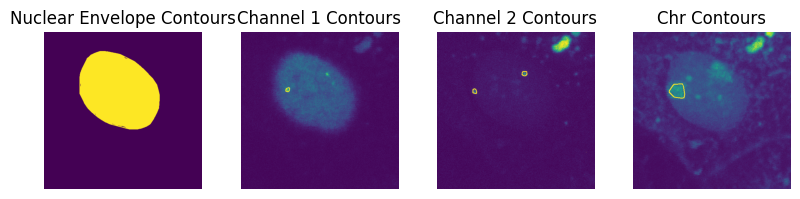

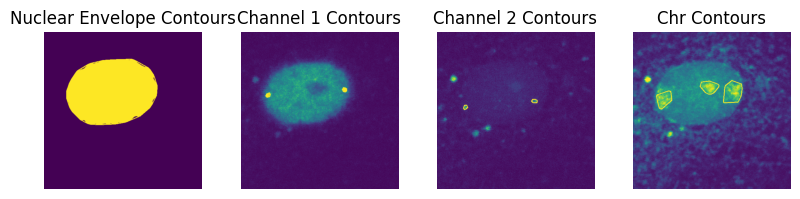

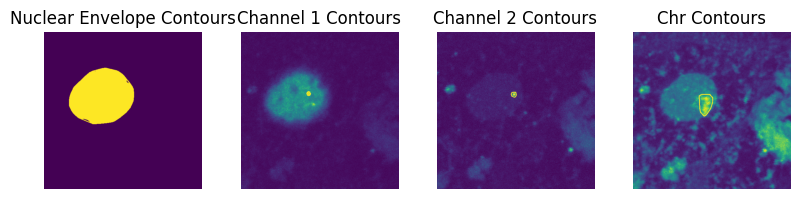

Skipping mHep_chr2_550_chr2_2_647_chr2_32_488_2_-_Position_44_tif_MIPs_series1_MIP.tif: No dots detected in 488 or 647 channels.
Skipping mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Position_33_tif_MIPs_series1_MIP.tif: No nuclear edges detected.


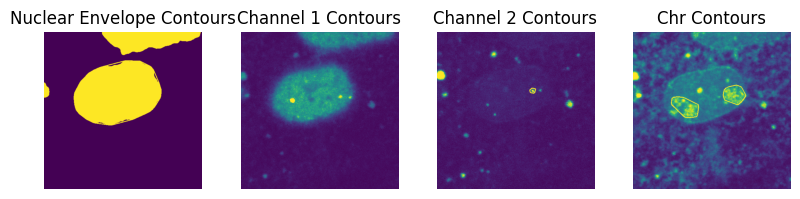

Skipping mHep_chr2_550_chr2_2_647_chr2_32_488_2_-_Position_15_tif_MIPs_series1_MIP.tif: No chromosome territory detected.


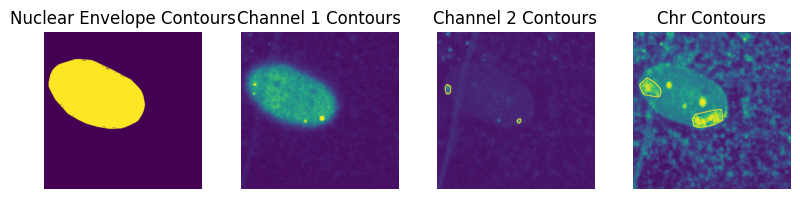

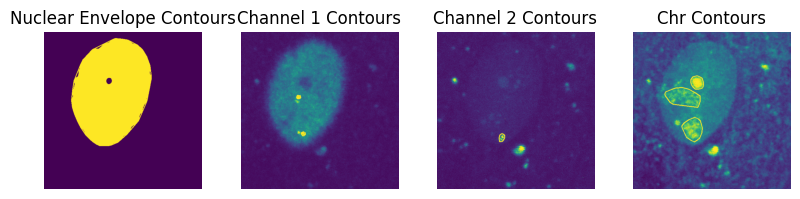

In [175]:
# Chr2_79 & Chr2_100 (DE threshold: nuclear: 80, dot_488: 180; dot_647: 60; chr_territory: 150 if load image.shape[4]) 
#(H1 threshold: nuclear: 80, dot_488: 180; dot_647: 60; chr_territory: 160 if load image.shape[4]) 
#(HB threshold: nuclear: 80, dot_488: 170; dot_647: 60; chr_territory: 160 if load image.shape[4]) 
#(iHep threshold: nuclear: 80, dot_488: 170; dot_647: 60; chr_territory: 160 if load image.shape[4]) 
#(mHep threshold: nuclear: 80, dot_488: 170; dot_647: 60; chr_territory: 160 if load image.shape[4]) 
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr2_100_chr2_79/"
#tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif")]

stage = 'mHep'
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif") and f.startswith((stage))]


print("dot: Chr2_79; dot: chr2_100")

cluster_488 = []
cluster_647 = []

for file in tiff_files:  # Using all TIFF files
    image_path = os.path.join(data_dir, file)
    try:
        # Load required channels using tifffile
        image = tiff.imread(image_path)
        if len(image.shape) < 3 or image.shape[0] < 7:
            print(f"Skipping {file}: Not enough channels ({image.shape})")
            continue

        dot_488 = load_image_tifffile(image_path, 1)
        dot_647 = load_image_tifffile(image_path, 2)
        chr_territory = load_image_tifffile(image_path, 4)
        nuclear = load_image_tifffile(image_path, 6)
        
        # Extract nuclear morphology
        nuclear_region, num_nuclei, df_nuclear_edges = extract_nuclear_morphology(nuclear)
#        nuclear_region, num_nuclei, df_nuclear_edges = extract_nuclear_morphology_iHepmHep(nuclear)


        # Check if nuclear region is empty
        if nuclear_region.size == 0:
            print(f"Skipping {file}: No nuclear region detected.")
            continue
        
        # Process chromosome territories within nuclear shape
        pixels_chr_territory, df_chr_territory = preprocess_image_within_chrterritory(chr_territory, nuclear_region)
#        pixels_chr_territory, df_chr_territory = preprocess_image_within_chrterritory_iHepmHep(chr_territory)

        # Check if chromosome territory is empty
        if df_chr_territory.empty:
            print(f"Skipping {file}: No chromosome territory detected.")
            continue
        
        # Process dot detection
        binary1, df_488 = preprocess_image_within_dot488(dot_488, nuclear_region, top_pct=1)
        binary2, df_647 = preprocess_image_within_dot647(dot_647, nuclear_region, top_pct=3)

        # Ensure dot detection is not empty
        if df_488.empty or df_647.empty:
            print(f"Skipping {file}: No dots detected in 488 or 647 channels.")
            continue

        # Compute nuclear centroid using region properties
        nuclear_centroid = calculate_nuclear_centroid(nuclear_region, nuclear)

        # Check if nuclear edges are empty
        if df_nuclear_edges.empty:
            print(f"Skipping {file}: No nuclear edges detected.")
            continue

        # Calculate distances per dot
        df_488 = calculate_distances(df_488, df_nuclear_edges, nuclear_centroid, df_chr_territory, file)
        df_647 = calculate_distances(df_647, df_nuclear_edges, nuclear_centroid, df_chr_territory, file)
        
        # Store results separately in two clusters
        cluster_488.append(df_488)
        cluster_647.append(df_647)
        
        # Draw contours
        draw_contours(
            [nuclear, dot_488, dot_647, chr_territory], 
            [nuclear_region, binary1, binary2, pixels_chr_territory], 
            ["Nuclear Envelope Contours", "Channel 1 Contours", "Channel 2 Contours", "Chr Contours"], 
            [(255, 255, 255), (255, 0, 0), (255, 0, 0), (255, 0, 0)]
        )

    except Exception as e:
        print(f"Error processing {file}: {e}")

# Concatenate all DataFrames and save separately
if cluster_488:
    df_cluster_488 = pd.concat(cluster_488, ignore_index=True)
    df_cluster_488.to_csv(os.path.join(data_dir, f"{stage}_cluster_647_farest_dist_saved.csv"), index=False)

if cluster_647:
    df_cluster_647 = pd.concat(cluster_647, ignore_index=True)
    df_cluster_647.to_csv(os.path.join(data_dir, f"{stage}_cluster_488_farest_dist_saved.csv"), index=False)

In [176]:
len(df_cluster_488['File_Name'].unique())

41

# organize the FISH results (in .cvs) and do statistics

In [6]:
#load the chr11 and chr2 tables
# Define stages
stages = ['H1','DE','HB','iHep','mHep']

# File paths for different Chr11 datasets
file_paths_chr11 = {
    "Chr11_88": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_88_chr11_41/{}_cluster_647_farest_dist_saved.csv",
    "Chr11_41_1": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_88_chr11_41/{}_cluster_550_farest_dist_saved.csv",
    "Chr11_41_2": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_11_chr11_41/{}_cluster_550_farest_dist_saved.csv", #(not good quality at H1 and DE stage）
    "Chr11_11": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_11_chr11_41/{}_cluster_647_farest_dist_saved.csv",
    "Chr11_107": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_107_chr11_119/{}_cluster_647_farest_dist_saved.csv",
    "Chr11_119": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr11_107_chr11_119/{}_cluster_550_farest_dist_saved.csv"
}

file_paths_chr2 = {
    "Chr2_100": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr2_100_chr2_79/{}_cluster_647_farest_dist_saved.csv",
    "Chr2_79": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr2_100_chr2_79/{}_cluster_488_farest_dist_saved.csv",
    "Chr2_2": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr2_2_chr2_32/{}_cluster_647_farest_dist_saved.csv",
    "Chr2_32": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/Chr2_2_chr2_32/{}_cluster_488_farest_dist_saved.csv",
}

# Function to load CSV files into a dictionary
def load_chr_data(file_paths):
    chr_data = {}
    for name, path_template in file_paths.items():
        df_list = []
        for stage in stages:
            path = path_template.format(stage)
            if os.path.exists(path):
                df = pd.read_csv(path)
                df["stage"] = stage  # Add stage as a new column
                df["Probe"] = name
                df_list.append(df)
        
        if df_list:
            chr_data[name] = pd.concat(df_list, ignore_index=True)
    return chr_data

# Load Chr11 and Chr2 data
Chr11 = load_chr_data(file_paths_chr11)
Chr2 = load_chr_data(file_paths_chr2)

# Remove specific stages from Chr11_41_2
Chr11["Chr11_41_2"] = Chr11["Chr11_41_2"][~Chr11["Chr11_41_2"]["stage"].isin(["H1", "DE"])] #(not good quality in H1 and DE stage）

# Combine Chr11_41_1 and Chr11_41_2 into a single DataFrame
Chr11["Chr11_41"] = pd.concat([Chr11["Chr11_41_1"], Chr11["Chr11_41_2"]], ignore_index=True)
Chr11["Chr11_41"]["Probe"] = "Chr11_41"  # Assign the probe name explicitly

# Remove original separate files to avoid duplication
del Chr11["Chr11_41_1"]
del Chr11["Chr11_41_2"]

In [7]:
# filter Chr11 dots
probes1 = ["Chr11_11", "Chr11_88", "Chr11_107", "Chr11_119", "Chr11_41"]
Chr11_filter = {}

for probe in probes1:
    if probe in Chr11:
        df = Chr11[probe].copy()

        # Step 1: keep top 2 Max_Intensity per File_Name
        df = df.sort_values(by=["File_Name", "Max_Intensity"], ascending=[True, False])
        df = df.groupby("File_Name").head(2)

        # Step 2: Drop rows where Area > 1000
        df = df[df["Area"] <= 1000]

        # Step 3: nuclear location ratio
        df["Ratio_of_far_from_Nuclear"] = (
            df["Dist_to_Nuclear_Centroid"] /
            (df["Dist_to_Nuclear_Centroid"] + df["Dist_to_Nuclear_Edge"])
        )

        # Step 5: CT location (edge-based, local radius)
        df["far_from_edge_of_CT"] = np.where(
            df["Dist_to_Chr_Territory_Centroid"] < df["Dist_Chr_Edge_to_Centroid"],
            df["Dist_to_Chr_Territory_Edge"] / df["Dist_Chr_Edge_to_Centroid"],
            -(df["Dist_to_Chr_Territory_Edge"] / df["Dist_Chr_Edge_to_Centroid"])
        )

        # ---------------- NEW PART ----------------
        # Step 5b: classify CT zone (inside / edge / outside)
        df["CT_zone"] = np.select(
            [
                df["Dist_to_Chr_Territory_Centroid"] < df["Dist_Chr_Edge_to_Centroid"],
                (df["Dist_to_Chr_Territory_Centroid"] >= df["Dist_Chr_Edge_to_Centroid"]) &
                (df["Dist_to_Chr_Territory_Centroid"] <  df["Max_Chr_Edge_to_Centroid"]),
                df["Dist_to_Chr_Territory_Centroid"] >= df["Max_Chr_Edge_to_Centroid"],
            ],
            ["inside", "edge", "outside"],
            default=np.nan
        )

        # Step 5c: CT location normalized by MAX radius
        df["far_from_edge_of_CT_maxiumdist"] = np.where(
            df["Dist_to_Chr_Territory_Centroid"] < df["Max_Chr_Edge_to_Centroid"],
            df["Dist_to_Chr_Territory_Edge"] / df["Max_Chr_Edge_to_Centroid"],
            -(df["Dist_to_Chr_Territory_Edge"] / df["Max_Chr_Edge_to_Centroid"])
        )

        # Safety: avoid divide-by-zero
        df.loc[df["Max_Chr_Edge_to_Centroid"] <= 0, "far_from_edge_of_CT_maxiumdist"] = np.nan
        df.loc[df["Dist_Chr_Edge_to_Centroid"] <= 0, "far_from_edge_of_CT"] = np.nan
        # ------------------------------------------------
        
        # Step 6: overrides (if localized to periphery, it should be inside of territory)
        mask = (
            df["stage"].isin(["HB", "iHep", "mHep"]) &
            (df["Ratio_of_far_from_Nuclear"] > 0.8)
        )
        df.loc[mask, ["far_from_edge_of_CT_maxiumdist", "far_from_edge_of_CT"]] = 0.1

        mask = (
            df["stage"].isin(["DE"]) &
            (df["Ratio_of_far_from_Nuclear"] > 0.9)
        )
        df.loc[mask, ["far_from_edge_of_CT_maxiumdist", "far_from_edge_of_CT"]] = 0.1


        Chr11_filter[probe] = df

In [8]:
Chr11_filter["Chr11_11"]

,Centroid_Y,Centroid_X,Max_Intensity,Area,File_Name,Dist_to_Nuclear_Centroid,Dist_to_Nuclear_Edge,Dist_Nuclear_Edge_to_Centroid,Dist_to_Chr_Territory_Edge,Dist_to_Chr_Territory_Centroid,Dist_Chr_Edge_to_Centroid,Max_Chr_Edge_to_Centroid,stage,Probe,Ratio_of_far_from_Nuclear,far_from_edge_of_CT,CT_zone,far_from_edge_of_CT_maxiumdist
295,132.982301,308.132743,255.0,226.0,DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_...,78.630401,52.645334,131.128202,4.583567,79.828466,83.918960,201.478427,DE,Chr11_11,0.598971,0.054619,inside,0.022750
324,127.839286,211.464286,241.0,168.0,DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_...,19.333077,105.742402,124.813611,38.422352,25.254208,28.696772,123.824002,DE,Chr11_11,0.154571,1.338909,inside,0.310298
325,218.026316,272.826316,233.0,190.0,DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_...,89.998224,35.695928,125.672030,58.380686,89.103959,75.227666,123.824002,DE,Chr11_11,0.716010,-0.776053,edge,0.471481
309,188.150000,234.770000,255.0,100.0,DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_...,76.516359,43.801546,119.008860,11.142504,54.362838,60.450113,105.462766,DE,Chr11_11,0.635952,0.184326,inside,0.105653
294,125.080000,267.470000,255.0,100.0,DE_chr11_488_chr11_11_647_chr11_chr41_550_1_-_...,130.979904,47.320686,178.098502,10.304722,47.715282,38.068522,57.854481,DE,Chr11_11,0.734602,-0.270689,edge,0.178115
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
548,182.641509,173.292453,255.0,106.0,mHep_chr11_488_chr11_11_647_chr11_41_550_2_-_P...,60.468076,7.270182,67.320730,52.686926,89.870206,37.314933,37.345159,mHep,Chr11_11,0.892672,0.100000,outside,0.100000
538,211.628788,288.992424,255.0,132.0,mHep_chr11_488_chr11_11_647_chr11_41_550_2_-_P...,54.481831,36.511538,90.918316,2.371224,18.706468,18.022057,61.800291,mHep,Chr11_11,0.598745,-0.131573,edge,0.038369
527,117.055046,245.366972,255.0,109.0,mHep_chr11_488_chr11_11_647_chr11_41_550_2_-_P...,74.058224,39.699445,112.034636,1.979271,84.563214,82.589163,132.845200,mHep,Chr11_11,0.651017,-0.023965,edge,0.014899
509,256.018519,371.564815,255.0,216.0,mHep_chr11_488_chr11_11_647_chr11_41_550_tif_M...,84.287806,55.955380,135.695395,4.096623,34.934113,31.308365,120.758976,mHep,Chr11_11,0.601012,-0.130848,edge,0.033924


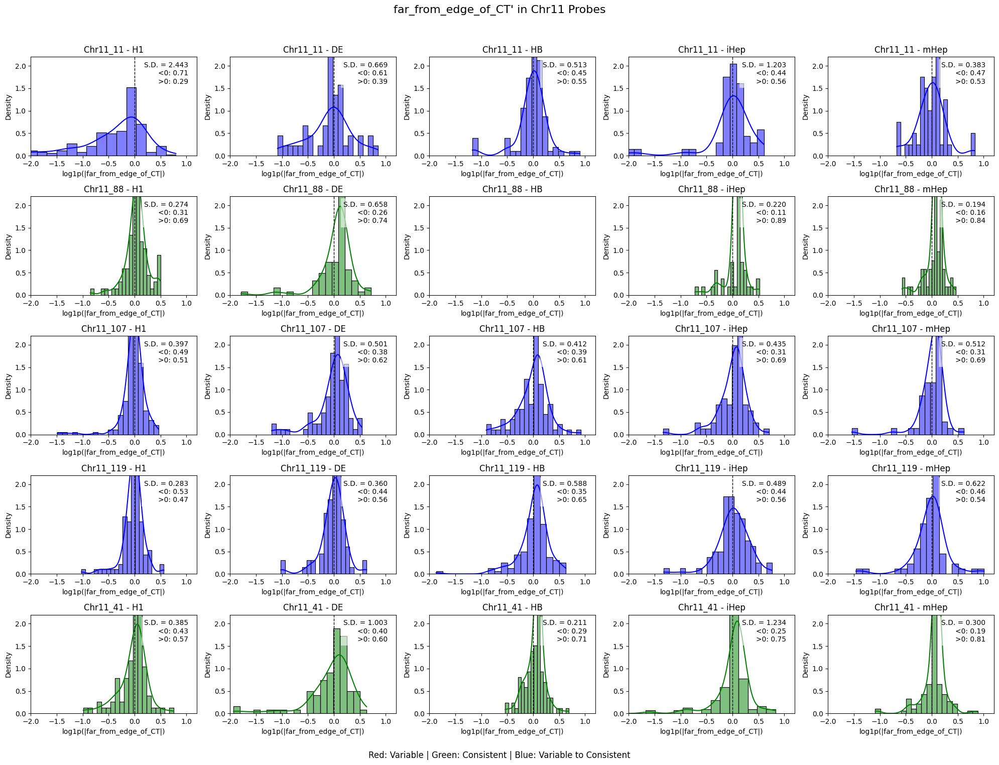

In [ ]:
#check the distribution of how far does the dot from chromosome center in chr11
stages = ['H1', 'DE', 'HB', 'iHep', 'mHep']

# Define colors for specific probes
probe_colors = {"Chr11_41": "green", "Chr11_88": "green"}

# Create subplots
fig, axes = plt.subplots(len(probes1), len(stages), 
                         figsize=(len(stages) * 4, len(probes1) * 3), 
                         sharex=False, sharey=False)
#fig.suptitle("Histogram of 'far_from_center_of_territory' in Chr11 Probes", fontsize=16)
fig.suptitle("far_from_edge_of_CT' in Chr11 Probes", fontsize=16)

# Plot histograms normalized by density
for i, probe in enumerate(probes1):
    for j, stage in enumerate(stages):
        ax = axes[i, j] if len(probes1) > 1 else axes[j]

        df = Chr11_filter[probe].copy()
        df = df[df['stage'] == stage]  # Filter by stage

        if not df.empty:
            color = probe_colors.get(probe, "blue")
            
            data = df['far_from_edge_of_CT']
            
            # Optional log-transform (handle zeros carefully)
            data_log = np.log1p(np.abs(data)) * np.sign(data)
            
            # Histogram with KDE
            sns.histplot(data_log, bins=20, kde=True, ax=ax, color=color, stat="density")
            
            # Compute variance and S.D. on original data
            var_val = np.var(data)
            sd_val = np.std(data)
            
            # Compute proportion <0 and >0
            prop_neg = (data < 0).sum() / len(data)
            prop_pos = (data > 0).sum() / len(data)
            
            # Add text annotation
            ax.text(0.95, 0.95, 
                    f"S.D. = {sd_val:.3f}\n<0: {prop_neg:.2f}\n>0: {prop_pos:.2f}", 
                    transform=ax.transAxes, ha='right', va='top', fontsize=10,
                    bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))
            
            # Draw vertical line at x = 0
            ax.axvline(x=0, color='black', linestyle='--', lw=1)

        ax.set_title(f"{probe} - {stage}")
        ax.set_xlabel("log1p(|far_from_edge_of_CT|)")
        ax.set_ylabel("Density")
        ax.set_xlim(-2, 1.2)
        ax.set_ylim(0, 2.2)

plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.text(0.5, -0.02, "Red: Variable | Green: Consistent | Blue: Variable to Consistent", 
         ha="center", fontsize=12, color="black")

# Save plot
plt.show()

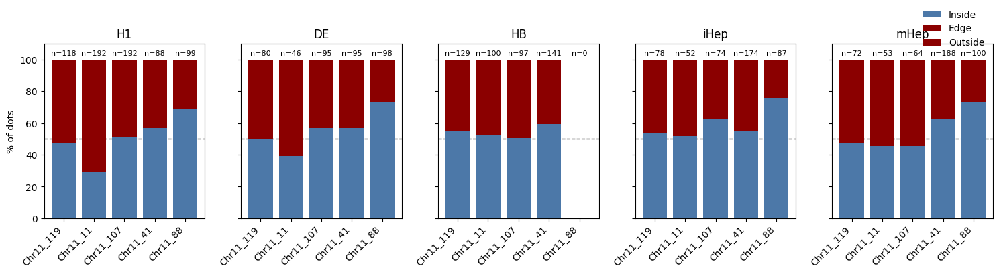

In [11]:
#barplot show the inside or outside
# barplot show inside / edge / outside
stages = ['H1', 'DE', 'HB', 'iHep', 'mHep']

probe_order = ['Chr11_119', 'Chr11_11', 'Chr11_107', 'Chr11_41', 'Chr11_88']

# Colors
inside_color = "#4C78A8"
edge_color = "darkred"
outside_color = "darkred"

fig, axes = plt.subplots(
    nrows=1, ncols=len(stages),
    figsize=(len(stages) * 3, 4.2),
    sharey=True
)

if len(stages) == 1:
    axes = [axes]

for j, stage in enumerate(stages):
    ax = axes[j]

    rows = []
    for probe in probe_order:
        if probe not in Chr11_filter:
            continue

        df = Chr11_filter[probe].copy()
        df = df[df["stage"] == stage].dropna(subset=["CT_zone"])

        inside_n = (df["CT_zone"] == "inside").sum()
        edge_n = (df["CT_zone"] == "edge").sum()
        outside_n = (df["CT_zone"] == "outside").sum()

        total = inside_n + edge_n + outside_n

        if total == 0:
            inside_pct = edge_pct = outside_pct = 0.0
        else:
            inside_pct = inside_n / total * 100
            edge_pct = edge_n / total * 100
            outside_pct = outside_n / total * 100

        rows.append({
            "probe": probe,
            "inside_pct": inside_pct,
            "edge_pct": edge_pct,
            "outside_pct": outside_pct,
            "n": total
        })

    plot_df = pd.DataFrame(rows).set_index("probe").reindex(probe_order)

    x = np.arange(len(plot_df.index))
    inside = plot_df["inside_pct"].fillna(0).values
    edge = plot_df["edge_pct"].fillna(0).values
    outside = plot_df["outside_pct"].fillna(0).values
    nvals = plot_df["n"].fillna(0).astype(int).values

    # Stack bars: inside → edge → outside
    ax.bar(x, inside, color=inside_color, label="Inside")
    ax.bar(x, edge, bottom=inside, color=edge_color, label="Edge")
    ax.bar(x, outside, bottom=inside + edge, color=outside_color, label="Outside")

    # 50% reference line
    ax.axhline(50, color="black", linestyle="--", linewidth=1, alpha=0.8, zorder=0)

    # annotate n
    for xi, n in enumerate(nvals):
        ax.text(xi, 102, f"n={n}", ha="center", va="bottom", fontsize=8)

    ax.set_title(stage)
    ax.set_xticks(x)
    ax.set_xticklabels(plot_df.index, rotation=45, ha="right")
    ax.set_ylim(0, 110)

    if j == 0:
        ax.set_ylabel("% of dots")

# shared legend
handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
fig.legend(by_label.values(), by_label.keys(),
           loc="upper right",
           bbox_to_anchor=(0.99, 0.98),
           frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

In [12]:
# Combine distribution after loop
Chr11_filter_combine = {}
Chr11_filter_combine['consistent'] = pd.concat([Chr11_filter['Chr11_41'], Chr11_filter['Chr11_88']])
Chr11_filter_combine['variable'] = pd.concat([Chr11_filter['Chr11_11'], Chr11_filter['Chr11_107'], Chr11_filter['Chr11_119']])

#downsampling

# Make a copy to avoid modifying the original dict
Chr11_filter_down = {}

# Find the minimum sample size across groups
min_size = min(len(Chr11_filter_combine['consistent']), len(Chr11_filter_combine['variable']))

# Fix random seed for reproducibility
np.random.seed(42)

for probe in ['consistent', 'variable']:
    df = Chr11_filter_combine[probe]
    if len(df) > min_size:
        Chr11_filter_down[probe] = df.sample(n=min_size, random_state=42)
    else:
        Chr11_filter_down[probe] = df.copy()

print("Consistent size_downsampling:", len(Chr11_filter_down['consistent']))
print("Variable size_downsampling:", len(Chr11_filter_down['variable']))
print("Consistent size:", len(Chr11_filter_combine['consistent']))
print("Variable size:", len(Chr11_filter_combine['variable']))

Consistent size_downsampling: 1070
Variable size_downsampling: 1070
Consistent size: 1070
Variable size: 1442


In [13]:
#calculate SD 
# Copy dataset first
Chr11_filter_down_clean = {
    "consistent": Chr11_filter_down["consistent"].copy(),
    "variable": Chr11_filter_down["variable"].copy()
}

stages = ['H1', 'DE', 'HB', 'iHep', 'mHep']

for probe in ["consistent", "variable"]:
    df = Chr11_filter_down_clean[probe].copy()
    remove_idx_all = []
    
    for stage in stages:
        mask_stage = df["stage"] == stage
        
        remove_idx = (
            df.loc[mask_stage]
              .sort_values("far_from_edge_of_CT")
              .head(3)
              .index
        )
        
        remove_idx_all.extend(remove_idx)
        
        print(f"\nRemoved points from {probe} - {stage}:")
        print(df.loc[remove_idx, ["stage", "far_from_edge_of_CT"]])
    
    Chr11_filter_down_clean[probe] = df.drop(index=remove_idx_all).copy()


Removed points from consistent - H1:
   stage  far_from_edge_of_CT
96    H1            -1.686634
96    H1             0.091646
81    H1            -1.429900
81    H1             0.136766
86    H1             0.162318
86    H1            -1.345726

Removed points from consistent - DE:
    stage  far_from_edge_of_CT
127    DE            -5.908328
127    DE             0.132712
217    DE            -5.513472
217    DE            -0.051275
191    DE             0.100000
191    DE            -4.977657

Removed points from consistent - HB:
    stage  far_from_edge_of_CT
606    HB            -0.711815
503    HB            -0.654682
657    HB            -0.473637

Removed points from consistent - iHep:
    stage  far_from_edge_of_CT
753  iHep           -14.496084
720  iHep            -4.065751
725  iHep            -3.854217

Removed points from consistent - mHep:
    stage  far_from_edge_of_CT
845  mHep            -1.969385
402  mHep            -1.764617
402  mHep             0.100000
401  mH

In [14]:
#plot barplot
# Settings
stages = ['H1', 'DE', 'HB', 'iHep', 'mHep']

probe_colors = {
    "consistent": "green",
    "variable": "blue"
}

outdir = "/home/xiangru.huo-umw/scHiC/scripts/plot2"
os.makedirs(outdir, exist_ok=True)

# Use cleaned dataset
Chr11_dict = Chr11_filter_down_clean


summary_list = []

for probe in ["consistent", "variable"]:
    df = Chr11_dict[probe].copy()
    
    for stage in stages:
        sub = df[df["stage"] == stage].copy()
        values = sub["far_from_edge_of_CT"].dropna()
        
        n_total = len(values)
        n_outside = (values < 0).sum()
        n_inside = (values > 0).sum()
        
        if n_inside > 0:
            outside_ratio = n_outside / (n_inside+n_outside)
            inside_ratio = 1- outside_ratio
        else:
            outside_inside_ratio = np.nan
        
        summary_list.append({
            "probe": probe,
            "stage": stage,
            "n": n_total,
            "SD": values.std(),
            "Variance": values.var(),
            "n_outside": n_outside,
            "n_inside": n_inside,
            "outside_ratio": outside_ratio,
            "inside_ratio": inside_ratio
        })

summary_df = pd.DataFrame(summary_list)

summary_df

,probe,stage,n,SD,Variance,n_outside,n_inside,outside_ratio,inside_ratio
0,consistent,H1,181,0.279262,0.077987,66,115,0.364641,0.635359
1,consistent,DE,187,0.524933,0.275555,59,128,0.315508,0.684492
2,consistent,HB,138,0.188839,0.035660,38,100,0.275362,0.724638
3,consistent,iHep,258,0.336704,0.113370,51,207,0.197674,0.802326
4,consistent,mHep,283,0.210572,0.044340,47,236,0.166078,0.833922
5,variable,H1,370,0.907855,0.824201,217,153,0.586486,0.413514
6,variable,DE,154,0.460688,0.212234,75,79,0.487013,0.512987
7,variable,HB,231,0.376718,0.141916,94,137,0.406926,0.593074
8,variable,iHep,143,0.372396,0.138679,58,85,0.405594,0.594406
9,variable,mHep,140,0.348502,0.121453,60,80,0.428571,0.571429


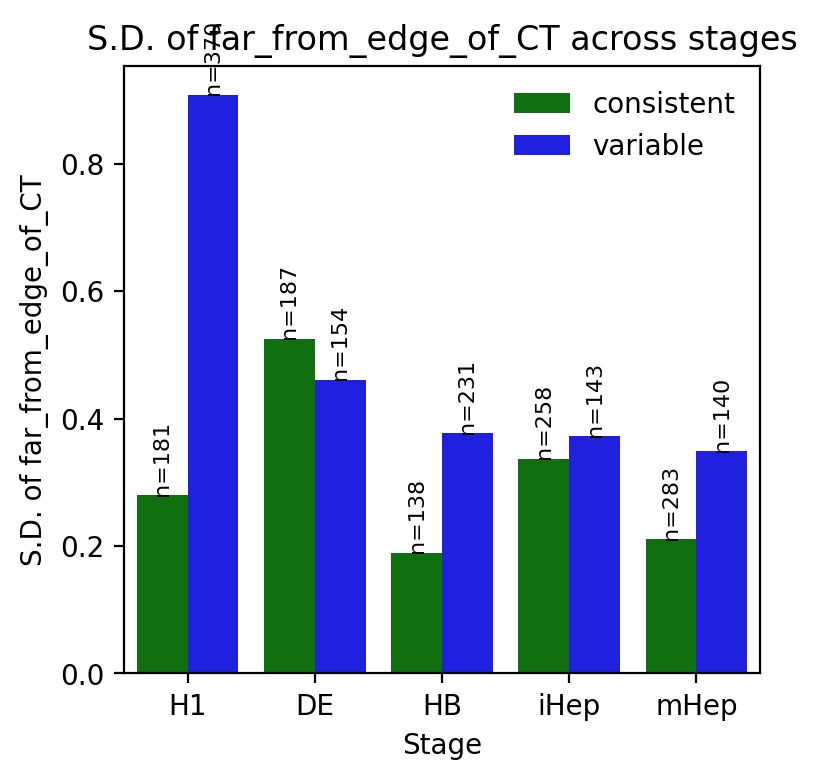

In [15]:
#plot barplots
plt.figure(figsize=(4, 4), dpi=200)

ax = sns.barplot(
    data=summary_df,
    x="stage",
    y="SD",
    hue="probe",
    order=stages,
    hue_order=["consistent", "variable"],
    palette=probe_colors,
    errorbar=None
)

for container, probe in zip(ax.containers, ["consistent", "variable"]):
    probe_df = summary_df[summary_df["probe"] == probe].set_index("stage").loc[stages]
    
    for bar, (_, row) in zip(container, probe_df.iterrows()):
        height = bar.get_height()
        if not np.isnan(height):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                height,
                f"n={int(row['n'])}",
                ha="center",
                va="bottom",
                fontsize=8,
                rotation=90
            )

ax.set_title("S.D. of far_from_edge_of_CT across stages")
ax.set_xlabel("Stage")
ax.set_ylabel("S.D. of far_from_edge_of_CT")

plt.legend(title="", frameon=False)
plt.tight_layout()

output_path = f"{outdir}/chr11_downsampling_clean_SD_barplot_with_n.pdf"
plt.savefig(output_path, dpi=200, format="pdf", bbox_inches="tight")
plt.show()

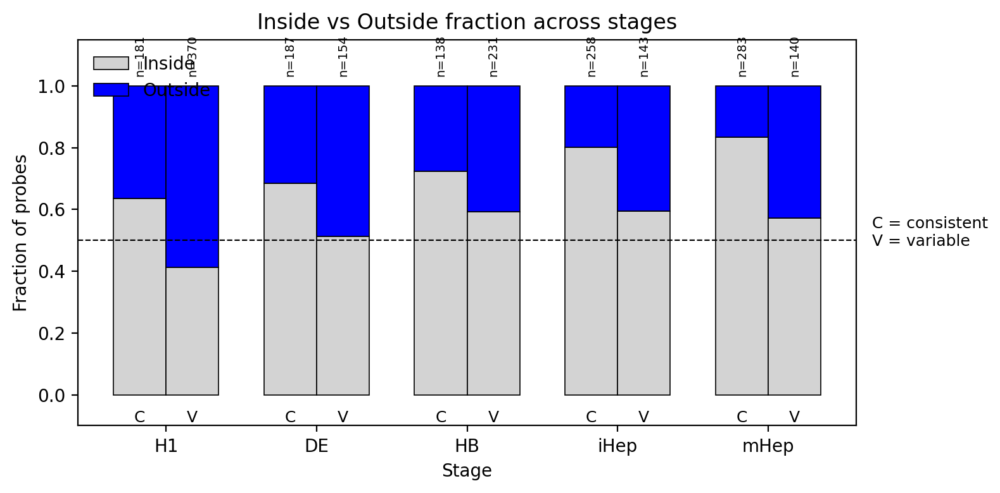

In [16]:
import numpy as np
import matplotlib.pyplot as plt

stages = ['H1', 'DE', 'HB', 'iHep', 'mHep']
probe_order = ["consistent", "variable"]

zone_colors = {
    "Inside": "lightgray",
    "Outside": "blue"
}

# Make sure summary_df is ordered correctly
plot_df = summary_df.copy()
plot_df["stage"] = pd.Categorical(plot_df["stage"], categories=stages, ordered=True)
plot_df["probe"] = pd.Categorical(plot_df["probe"], categories=probe_order, ordered=True)
plot_df = plot_df.sort_values(["stage", "probe"])

# x positions
x = np.arange(len(stages))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(8, 4), dpi=200)

for k, probe in enumerate(probe_order):
    sub = (
        plot_df[plot_df["probe"] == probe]
        .set_index("stage")
        .loc[stages]
        .reset_index()
    )
    
    # side-by-side position
    offset = -bar_width / 2 if probe == "consistent" else bar_width / 2
    xpos = x + offset
    
    inside = sub["inside_ratio"].values
    outside = sub["outside_ratio"].values
    
    # stacked bars
    ax.bar(
        xpos,
        inside,
        width=bar_width,
        color=zone_colors["Inside"],
        edgecolor="black",
        linewidth=0.6,
        label="Inside" if k == 0 else None
    )
    
    ax.bar(
        xpos,
        outside,
        width=bar_width,
        bottom=inside,
        color=zone_colors["Outside"],
        edgecolor="black",
        linewidth=0.6,
        label="Outside" if k == 0 else None
    )
    
    # label probe type below/above bar
    for i, row in sub.iterrows():
        ax.text(
            xpos[i],
            -0.05,
            "C" if probe == "consistent" else "V",
            ha="center",
            va="top",
            fontsize=9
        )
        
        ax.text(
            xpos[i],
            1.03,
            f"n={int(row['n'])}",
            ha="center",
            va="bottom",
            fontsize=7,
            rotation=90
        )

ax.axhline(0.5, color="black", linestyle="--", linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels(stages)
ax.set_ylim(-0.1, 1.15)

ax.set_xlabel("Stage")
ax.set_ylabel("Fraction of probes")
ax.set_title("Inside vs Outside fraction across stages")

ax.legend(frameon=False, loc="upper left")

# Add explanation for C/V
ax.text(
    1.02, 0.5,
    "C = consistent\nV = variable",
    transform=ax.transAxes,
    ha="left",
    va="center",
    fontsize=9
)

plt.tight_layout()

output_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/chr11_downsampling_inside_outside_grouped_stacked_barplot.pdf"
plt.savefig(output_path, dpi=200, format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
plt.figure(figsize=(6.5, 4), dpi=200)

ax = sns.barplot(
    data=summary_df,
    x="stage",
    y="outside_inside_ratio",
    hue="probe",
    order=stages,
    hue_order=["consistent", "variable"],
    palette=probe_colors,
    errorbar=None
)

ax.axhline(1, color="black", linestyle="--", linewidth=1)

ax.set_title("Outside / Inside ratio across stages")
ax.set_xlabel("Stage")
ax.set_ylabel("Outside / Inside ratio")

plt.legend(title="", frameon=False)
plt.tight_layout()

output_path = f"{outdir}/chr11_downsampling_clean_outside_inside_ratio_barplot.pdf"
plt.savefig(output_path, dpi=200, format="pdf", bbox_inches="tight")
plt.show()

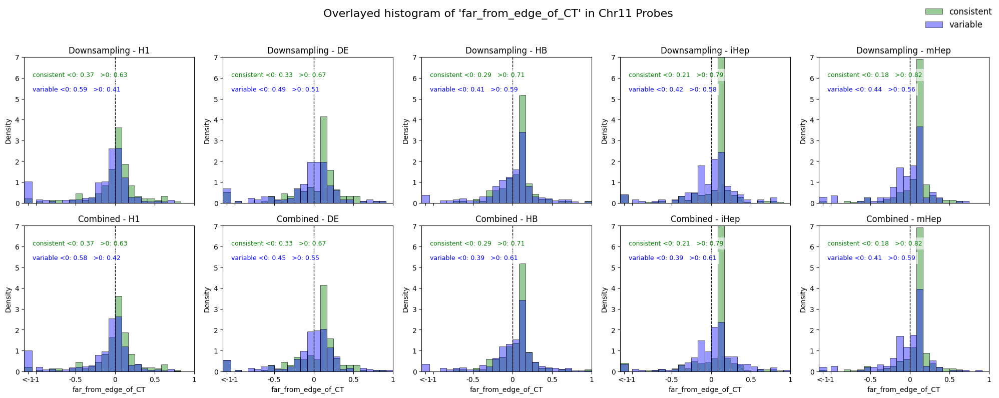

In [17]:
stages = ['H1', 'DE', 'HB', 'iHep', 'mHep']

probe_colors = {
    "consistent": "green",
    "variable": "blue"
}

datasets = {
    "Downsampling": Chr11_filter_down,
    "Combined": Chr11_filter_combine
}

fig, axes = plt.subplots(
    len(datasets), len(stages),
    figsize=(len(stages) * 4, len(datasets) * 4),
    sharex=True,
    sharey=False
)

fig.suptitle("Overlayed histogram of 'far_from_edge_of_CT' in Chr11 Probes", fontsize=16)

if len(datasets) == 1:
    axes = np.array([axes])

for i, (ds_name, Chr11_dict) in enumerate(datasets.items()):
    for j, stage in enumerate(stages):

        ax = axes[i, j]

        for probe in ['consistent', 'variable']:

            df = Chr11_dict[probe].copy()
            df = df[df['stage'] == stage]

            if not df.empty:

                color = probe_colors[probe]
                data = df['far_from_edge_of_CT'].dropna()

                # collapse all values < -1 to -1.1 for display only
                data_plot = data.copy()
                data_plot[data_plot < -1] = -1.1

                # one narrow bin around -1.1, then normal bins from -1 to 1
                bins = np.concatenate([
                    [-1.15, -1.05],          # collapsed bin centered at -1.1
                    np.linspace(-1, 1, 25)
                ])

                sns.histplot(
                    data_plot,
                    bins=bins,
                    kde=False,
                    ax=ax,
                    color=color,
                    stat="density",
                    alpha=0.4,
                    label=probe if (i == 0 and j == 0) else None
                )

                # proportions still from original data
                prop_neg = (data < 0).mean()
                prop_pos = (data > 0).mean()

                ax.text(
                    0.05,
                    0.90 if probe == "consistent" else 0.80,
                    f"{probe} <0: {prop_neg:.2f}   >0: {prop_pos:.2f}",
                    transform=ax.transAxes,
                    ha='left',
                    va='top',
                    fontsize=9,
                    color=color,
                    bbox=dict(facecolor='white', alpha=0.6, edgecolor='none')
                )

        ax.axvline(x=0, color='black', linestyle='--', lw=1)
        ax.set_title(f"{ds_name} - {stage}")
        ax.set_xlabel("far_from_edge_of_CT")
        ax.set_ylabel("Density")
        ax.set_xlim(-1.15, 1)
        ax.set_ylim(0, 7)

        ax.set_xticks([-1.1, -1, -0.5, 0, 0.5, 1])
        ax.set_xticklabels(["<-1", "-1", "-0.5", "0", "0.5", "1"])

fig.legend(loc='upper right', fontsize=12, frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.95])
#output_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/chr11_probes_territory_overlay_comparison_far_to_edge_nolog.pdf"
plt.savefig(output_path, dpi=200, format="pdf", bbox_inches="tight")
plt.show()

In [18]:
#filter chr2 dots
probes2 = ["Chr2_100", "Chr2_79", "Chr2_2", "Chr2_32","Chr2_155"]
Chr2_filter = {}

for probe in probes2:
    if probe in Chr2:  # Ensure the probe exists in the dataset
        df = Chr2[probe].copy()

        # Step 1: Select only two rows with the largest Max_Intensity when there are more than 2 duplicates of File_Name
        df = df.sort_values(by=["File_Name", "Max_Intensity"], ascending=[True, False])  # Sort by File_Name and Max_Intensity
        df = df.groupby("File_Name").head(2)  # Keep only the top 2 per File_Name

        # Step 2: Drop rows where Area > 1000
        df = df[df["Area"] <= 1000]
                
        # Step 4: Compute nuclear location ratio
        df['Ratio_of_far_from_Nuclear'] = df['Dist_to_Nuclear_Centroid'] / (df['Dist_to_Nuclear_Centroid']+df['Dist_to_Nuclear_Edge'])
        
        # Step 5: Compute chromosome territory location
        df['far_from_center_of_territory'] = np.where(
            df['Dist_to_Chr_Territory_Centroid'] < df['Dist_Chr_Edge_to_Centroid'],
            df['Dist_to_Chr_Territory_Centroid'] / df['Dist_Chr_Edge_to_Centroid'],  # Inside of territory
            - (df['Dist_to_Chr_Territory_Edge'] / df['Dist_Chr_Edge_to_Centroid'])   # outside of territory
        )
        
        # Step 5: CT location (edge-based)
        df['far_from_edge_of_CT'] = np.where(
            df['Dist_to_Chr_Territory_Centroid'] < df['Dist_Chr_Edge_to_Centroid'],
            df['Dist_to_Chr_Territory_Edge']/ df['Dist_Chr_Edge_to_Centroid'] ,
            -(df['Dist_to_Chr_Territory_Edge']/ df['Dist_Chr_Edge_to_Centroid'] )
        )

        # Step 6: overrides
        mask = (
            df["stage"].isin(["HB", "iHep", "mHep"]) &
            (df["Ratio_of_far_from_Nuclear"] > 0.8)
        )
        df.loc[mask, ["far_from_edge_of_CT_maxiumdist", "far_from_edge_of_CT"]] = 0.1

        mask = (
            df["stage"].isin(["DE"]) &
            (df["Ratio_of_far_from_Nuclear"] > 0.9)
        )
        df.loc[mask, ["far_from_edge_of_CT_maxiumdist", "far_from_edge_of_CT"]] = 0.1


        # Store filtered DataFrame
        Chr2_filter[probe] = df

In [19]:
Chr2_filter["Chr2_100"]

,Centroid_Y,Centroid_X,Max_Intensity,Area,File_Name,Dist_to_Nuclear_Centroid,Dist_to_Nuclear_Edge,Dist_Nuclear_Edge_to_Centroid,Dist_to_Chr_Territory_Edge,Dist_to_Chr_Territory_Centroid,Dist_Chr_Edge_to_Centroid,Max_Chr_Edge_to_Centroid,stage,Probe,Ratio_of_far_from_Nuclear,far_from_center_of_territory,far_from_edge_of_CT,far_from_edge_of_CT_maxiumdist
186,203.153226,164.685484,255.0,124.0,DE_chr2_550_chr2_100_647_chr2_79_488_-_Positio...,122.464465,18.725345,141.189436,0.702400,88.060825,88.569632,127.293741,DE,Chr2_100,0.867375,0.994255,0.007930,NaN
205,290.329341,279.377246,255.0,167.0,DE_chr2_550_chr2_100_647_chr2_79_488_-_Positio...,55.489537,62.057096,109.314706,14.564718,46.088205,38.863140,172.484948,DE,Chr2_100,0.472064,-0.374769,-0.374769,NaN
194,246.298578,303.635071,255.0,211.0,DE_chr2_550_chr2_100_647_chr2_79_488_-_Positio...,60.922647,46.255878,106.758559,29.853029,97.145159,84.866144,122.108082,DE,Chr2_100,0.568422,-0.351766,-0.351766,NaN
181,259.424581,159.251397,255.0,179.0,DE_chr2_550_chr2_100_647_chr2_79_488_-_Positio...,93.497507,26.290022,116.228297,38.450402,55.526337,17.121435,27.174533,DE,Chr2_100,0.780528,-2.245746,-2.245746,NaN
204,192.625000,166.045455,255.0,176.0,DE_chr2_550_chr2_100_647_chr2_79_488_-_Positio...,226.974160,19.013320,245.803271,2.612376,202.335602,204.941578,222.455485,DE,Chr2_100,0.922706,0.987284,0.100000,0.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
372,202.798077,218.692308,255.0,104.0,mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Pos...,33.086847,62.128441,93.855848,3.973574,37.267383,33.746584,40.670545,mHep,Chr2_100,0.347495,-0.117747,-0.117747,NaN
353,221.761290,208.600000,255.0,155.0,mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Pos...,43.634803,63.518229,107.063713,0.465814,16.595977,16.152993,123.842991,mHep,Chr2_100,0.407219,-0.028838,-0.028838,NaN
375,213.672414,185.801724,255.0,116.0,mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Pos...,37.612474,47.211283,25.953560,0.701038,26.966246,27.663652,118.211883,mHep,Chr2_100,0.443419,0.974790,0.025341,NaN
376,332.316239,201.572650,255.0,117.0,mHep_chr2_550_chr2_100_647_chr2_79_488_2_-_Pos...,139.211895,37.686184,176.651907,4.769085,94.426426,92.032016,118.211883,mHep,Chr2_100,0.786961,-0.051820,-0.051820,NaN


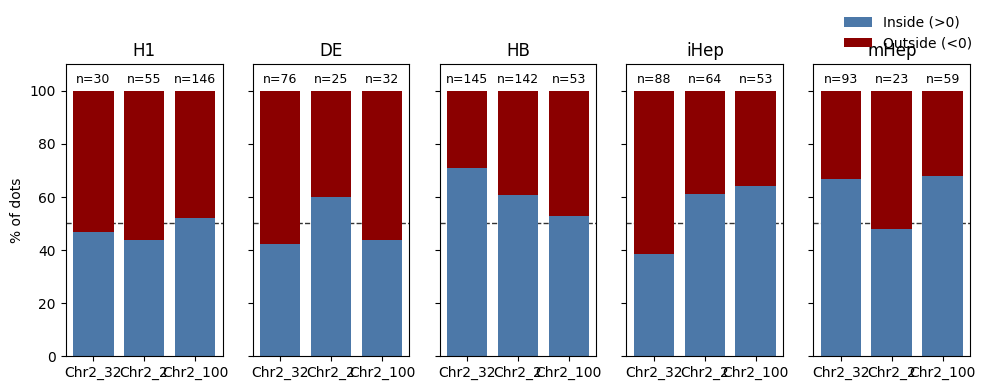

In [20]:
#bar plot
stages = ['H1', 'DE', 'HB', 'iHep', 'mHep']

# --- fixed probe order, ONLY these three ---
probe_order = ['Chr2_32', 'Chr2_2', 'Chr2_100']

# Colors
inside_color = "#4C78A8"   # inside (>0)
outside_color = "darkred"  # outside (<0)
zero_color = "#BDBDBD"     # exactly 0 (optional)

fig, axes = plt.subplots(
    nrows=1, ncols=len(stages),
    figsize=(len(stages) * 2, 4.0),
    sharey=True
)
if len(stages) == 1:
    axes = [axes]

for j, stage in enumerate(stages):
    ax = axes[j]

    rows = []
    for probe in probe_order:
        if probe not in Chr2_filter:
            rows.append({"probe": probe, "inside_pct": 0, "outside_pct": 0, "zero_pct": 0, "n": 0})
            continue

        df = Chr2_filter[probe].copy()
        df = df[df["stage"] == stage].dropna(subset=["far_from_edge_of_CT"])

        inside_n = (df["far_from_edge_of_CT"] > 0).sum()
        outside_n = (df["far_from_edge_of_CT"] < 0).sum()
        zero_n = (df["far_from_edge_of_CT"] == 0).sum()
        total = inside_n + outside_n + zero_n

        if total == 0:
            inside_pct = outside_pct = zero_pct = 0.0
        else:
            inside_pct = inside_n / total * 100
            outside_pct = outside_n / total * 100
            zero_pct = zero_n / total * 100

        rows.append({
            "probe": probe,
            "inside_pct": inside_pct,
            "outside_pct": outside_pct,
            "zero_pct": zero_pct,
            "n": total
        })

    plot_df = pd.DataFrame(rows).set_index("probe").reindex(probe_order)

    x = np.arange(len(plot_df.index))
    inside = plot_df["inside_pct"].values
    outside = plot_df["outside_pct"].values
    zero = plot_df["zero_pct"].values
    nvals = plot_df["n"].astype(int).values

    # stacked bars
    ax.bar(x, inside, color=inside_color, label="Inside (>0)")
    ax.bar(x, outside, bottom=inside, color=outside_color, label="Outside (<0)")
    if np.any(zero > 0):
        ax.bar(x, zero, bottom=inside + outside, color=zero_color, label="Zero (=0)")

    # n annotation
    for xi, n in enumerate(nvals):
        ax.text(xi, 102, f"n={n}", ha="center", va="bottom", fontsize=9)

    # 50% reference
    ax.axhline(50, color="black", linestyle="--", linewidth=1, alpha=0.8, zorder=0)

    ax.set_title(stage)
    ax.set_xticks(x)
    ax.set_xticklabels(plot_df.index, rotation=0)
    ax.set_ylim(0, 110)
    if j == 0:
        ax.set_ylabel("% of dots")

# Legend (shared)
handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
fig.legend(by_label.values(), by_label.keys(),
           loc="upper right", bbox_to_anchor=(0.99, 0.98),
           frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.92])

output_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/chr2_probes_inside_outside_by_stage.pdf"
plt.savefig(output_path, dpi=200, format="pdf", bbox_inches="tight")
plt.show()

In [21]:
#combined
Chr2_filter_combine = {}
Chr2_filter_combine['variable'] = pd.concat([Chr2_filter['Chr2_100'], Chr2_filter['Chr2_32'], Chr2_filter['Chr2_2']])

print("Variable size:", len(Chr2_filter_combine['variable']))

Variable size: 1084


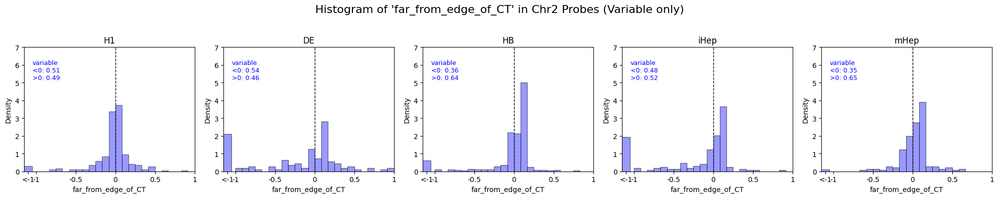

In [22]:
stages = ['H1', 'DE', 'HB', 'iHep', 'mHep']

# Define color
probe_color = "blue"

# Create subplots
fig, axes = plt.subplots(
    1, len(stages),
    figsize=(len(stages) * 4, 4),
    sharex=True,
    sharey=False
)

fig.suptitle(
    "Histogram of 'far_from_edge_of_CT' in Chr2 Probes (Variable only)",
    fontsize=16
)

for j, stage in enumerate(stages):

    ax = axes[j] if len(stages) > 1 else axes

    df = Chr2_filter_combine['variable'].copy()
    df = df[df['stage'] == stage]

    if not df.empty:

        data = df['far_from_edge_of_CT'].dropna()

        # Collapse all values < -1 to -1.1 for plotting only
        data_plot = data.copy()
        data_plot[data_plot < -1] = -1.1

        # One narrow collapsed bin at -1.1, then normal bins from -1 to 1
        bins = np.concatenate([
            [-1.15, -1.05],
            np.linspace(-1, 1, 25)
        ])

        sns.histplot(
            data_plot,
            bins=bins,
            kde=False,
            ax=ax,
            color=probe_color,
            stat="density",
            alpha=0.4
        )

        # proportions from ORIGINAL values
        prop_neg = (data < 0).mean()
        prop_pos = (data > 0).mean()

        ax.text(
            0.05, 0.9,
            f"variable\n<0: {prop_neg:.2f}\n>0: {prop_pos:.2f}",
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=9,
            color=probe_color,
            bbox=dict(facecolor='white', alpha=0.6, edgecolor='none')
        )

    # Vertical line at 0
    ax.axvline(x=0, color='black', linestyle='--', lw=1)

    ax.set_title(stage)
    ax.set_xlabel("far_from_edge_of_CT")
    ax.set_ylabel("Density")

    ax.set_xlim(-1.15, 1)
    ax.set_ylim(0, 7)

    ax.set_xticks([-1.1, -1, -0.5, 0, 0.5, 1])
    ax.set_xticklabels(["<-1", "-1", "-0.5", "0", "0.5", "1"])

plt.tight_layout(rect=[0, 0, 1, 0.95])

output_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/chr2_probes_territory_variable_overlay_far_toedge_nolog.pdf"

plt.savefig(output_path, dpi=200, format="pdf", bbox_inches="tight")
plt.show()